# Tugas 2 — Pendekatan Non-Deep Learning: Inspeksi Kemasan Kubus Gingerbread 3D

Notebook ini mendokumentasikan alur kerja Non-Deep Learning yang **kami** bangun untuk memprediksi jumlah total gingerbread, jumlah cacat, serta jumlah desain unik pada tiga sisi kemasan kubus (`front`, `right`, `top`). Selain pipeline utama berbasis Multi-Template Coarse-to-Fine NCC (`predict_cube_non_dl`), **kami** turut mengevaluasi tiga model pembanding resmi (`SIFT + RANSAC`, `ORB + RANSAC`, dan `Contour + HSV`), studi generalisasi `1-ref` vs `7-ref`, progresi optimasi `v1 -> v2 -> v3`, serta galeri analisis kegagalan.

### 1. Inisialisasi Lingkungan, Log Reprodusibilitas, Referensi `template_all`, dan Dataset
Kami menyiapkan jalur modul `src.task2_non_dl`, mencatat versi pustaka, *seed* deterministik OpenCV (`cv2.setRNGSeed(42)`), serta spesifikasi perangkat komputasi sesuai pedoman eksperimen. Selanjutnya kami memuat ketujuh desain referensi (`template_all/`) beserta indeks `100` citra berlabel (`70` train, `15` val, `15` test) dan `200` citra *hidden*.

In [1]:
import hashlib
import io
import json
import os
import platform
import sys
import time
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

cv2.setRNGSeed(42)

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "task2_non_dl").exists():
    if (ROOT.parent / "src" / "task2_non_dl").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.task2_non_dl import (
    CANONICAL_FACE_SIZE,
    align_and_score_cookie,
    compute_vanishing_center,
    extract_cube_hexagon,
    fit_background_model,
    predict_cube_contour_hsv,
    predict_cube_non_dl,
    predict_cube_orb_ransac,
    predict_cube_sift_ransac,
    prepare_reference_cache,
    rectify_face,
    segment_cube_faces,
    segment_face_cookies,
)
from src.task2_non_dl.baselines import (
    _build_feature_config,
    _extract_contour_zone_stats,
    _prepare_contour_hsv_refs,
    _prepare_feature_refs,
    _score_contour_hsv_cookie,
    _umeyama_2d_similarity,
)
from src.task2_non_dl.detector import (
    _bbox_gap,
    _crop_tight_rgba,
    _extract_aligned_design_stats,
    _fit_shading_affine,
    _major_axis_angle_deg,
    _match_template_coarse,
    _match_template_fine,
    _oriented_aspect_ratio,
    _rotate_crop_patch,
)
from src.task2_non_dl.evaluate_and_visualize import (
    FACES,
    cube_columns,
    evaluate_cube_dataframe,
    load_zip_references,
    validate_cube_predictions,
)

# Dukung jalur lokal repositori maupun Google Colab Drive jika dijalankan di cloud.
def _resolve_zip(filename: str) -> Path:
    candidates = [
        ROOT / "data" / filename,
        Path("/content/drive/MyDrive/COMVIS/Mini_Project/data") / filename,
        Path("/content/data") / filename,
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(
        f"Berkas dataset '{filename}' tidak ditemukan di {ROOT / 'data'}. "
        "Letakkan arsip zip resmi pada folder data/ (atau mount Google Drive di Colab)."
    )

TRAIN_ZIP = _resolve_zip("gingerbread_seed2026_students_training.zip")
HIDDEN_ZIP = _resolve_zip("hidden_students.zip")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(TRAIN_ZIP) as zf:
    references = load_zip_references(zf)
    annotations = json.loads(zf.read("cube_annotations.json"))

truth_rows = []
for ann in annotations:
    gt = {"image_id": Path(ann["image"]).stem, "split": ann["split"]}
    for f in ann["faces"]:
        fn = f["name"]
        gt[f"{fn}_total"] = int(f["total_instances"])
        gt[f"{fn}_defective"] = int(len(f["defective_instance_ids"]))
        gt[f"{fn}_design_count"] = int(len(f["counts_by_design"]))
    truth_rows.append(gt)
df_truth = pd.DataFrame(truth_rows)

print("=== Log Lingkungan Eksekusi & Reprodusibilitas ===")
print(
    f"Perangkat : Python {sys.version.split()[0]} | OS {platform.system()} {platform.release()} | "
    f"CPU {platform.processor() or 'unknown'} ({os.cpu_count()} logical cores)"
)
print(
    f"Pustaka   : OpenCV {cv2.__version__} | NumPy {np.__version__} | Pandas {pd.__version__} | "
    f"Seed OpenCV RNG=42 | Model Pralatih DL=Tidak Ada (100% Classical CV)"
)
print(f"Dataset   : {len(annotations)} kubus berlabel ({df_truth['split'].value_counts().to_dict()})")
print(f"Referensi : {[(k, v['name'], v['rgba'].shape) for k, v in references.items()]}")

=== Log Lingkungan Eksekusi & Reprodusibilitas ===
Perangkat : Python 3.13.14 | OS Windows 11 | CPU ARMv8 (64-bit) Family 8 Model 1 Revision 201, Qualcomm Technologies Inc (12 logical cores)
Pustaka   : OpenCV 4.13.0 | NumPy 2.4.2 | Pandas 3.0.0 | Seed OpenCV RNG=42 | Model Pralatih DL=Tidak Ada (100% Classical CV)
Dataset   : 100 kubus berlabel ({'train': 70, 'test': 15, 'val': 15})
Referensi : [(1, 'blue_wizard', (512, 256, 4)), (2, 'brown_hat_gnome', (512, 256, 4)), (3, 'green_hat_elf', (512, 256, 4)), (4, 'pilgrim', (512, 256, 4)), (5, 'santa', (512, 256, 4)), (6, 'striped_hat_elf', (512, 256, 4)), (7, 'witch', (512, 256, 4))]


### 2. Tahap 1 — Rekonstruksi Geometri 3D Kubus & Rektifikasi Homography
Kami memodelkan iluminasi latar belakang memakai regresi kuadratik-radial $B(u,v) = c_0 + c_1 u + c_2 v + c_3 (u^2 + v^2)$ per kanal RGB dengan *inlier re-fit* dua tahap agar gradasi bayangan tersingkirkan. Selanjutnya, kami mengekstraksi 6 sudut terluar kubus pada presisi sub-piksel lewat regresi garis Huber (`cv2.fitLine`), mencari titik temu tiga rusuk dalam (`v_center`) melalui proyeksi vanishing point homogen beserta disambiguasi paritas (`var_even < 0.82 * var_odd`), lalu meluruskan sisi `front`, `right`, dan `top` ke bidang kanonik `384x384`.

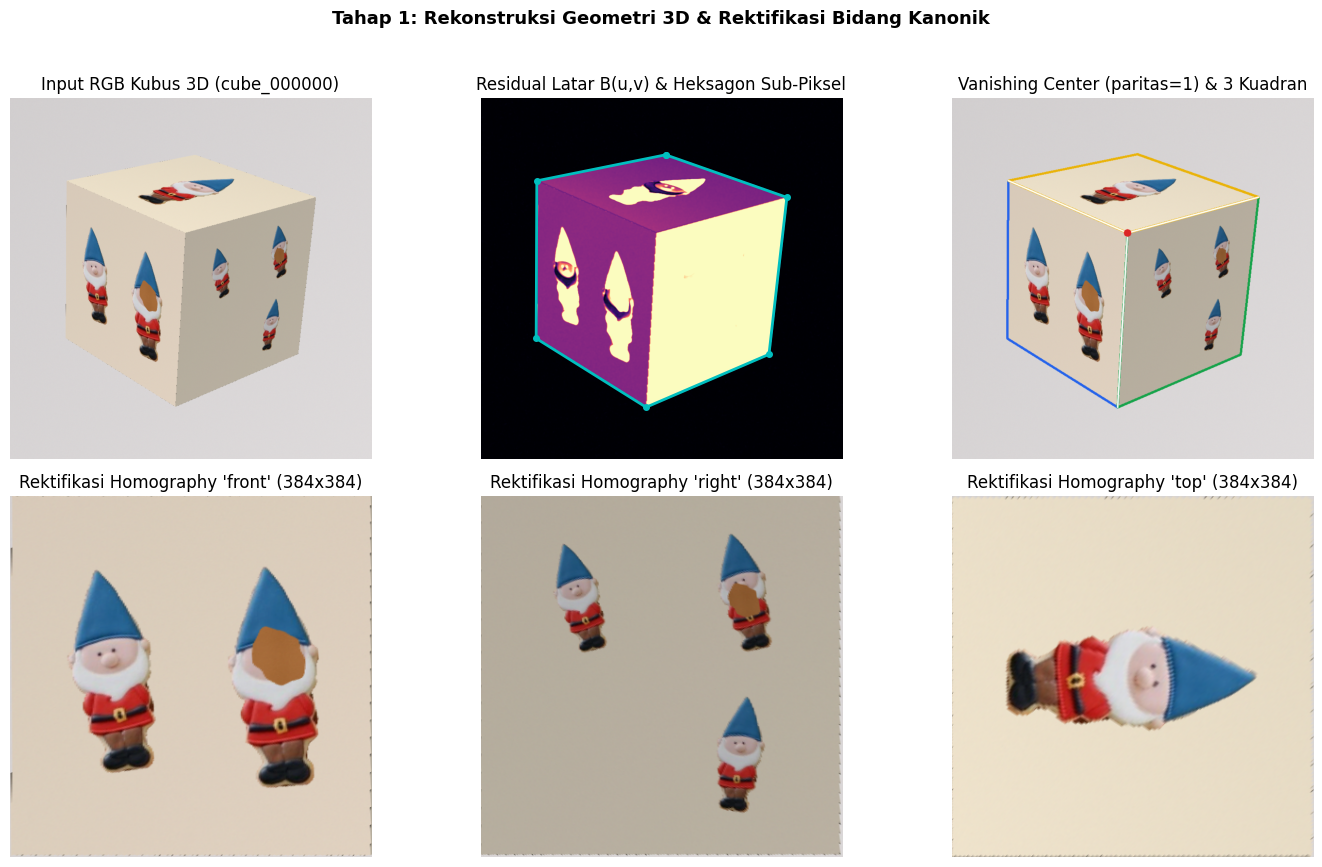

In [2]:
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    sample_ann = annotations[0]
    with Image.open(io.BytesIO(zf.read(sample_ann["image"]))) as im:
        sample_rgb = np.asarray(im.convert("RGB"))

bg_model, dist_map = fit_background_model(sample_rgb)
hex_pts, fg_mask = extract_cube_hexagon(sample_rgb, dist_map=dist_map)
v_center, parity = compute_vanishing_center(hex_pts, rgb=sample_rgb)
face_quads = segment_cube_faces(sample_rgb, hex_pts, v_center, parity=parity)
warped_faces = {fn: rectify_face(sample_rgb, face_quads[fn], CANONICAL_FACE_SIZE)[0] for fn in FACES}

fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.8))
axes[0, 0].imshow(sample_rgb)
axes[0, 0].set_title(f"Input RGB Kubus 3D ({Path(sample_ann['image']).stem})")

axes[0, 1].imshow(dist_map, cmap="magma", vmin=0, vmax=65)
axes[0, 1].plot(np.r_[hex_pts[:, 0], hex_pts[0, 0]], np.r_[hex_pts[:, 1], hex_pts[0, 1]], "c-o", lw=2, ms=4)
axes[0, 1].set_title("Residual Latar B(u,v) & Heksagon Sub-Piksel")

overlay_q = sample_rgb.copy()
face_cols = {"front": (37, 99, 235), "right": (22, 163, 74), "top": (234, 179, 8)}
for fn in FACES:
    cv2.polylines(overlay_q, [np.round(face_quads[fn]).astype(np.int32)], True, face_cols[fn], 4)
for idx_v in range(parity, 6, 2):
    p_end = tuple(np.round(hex_pts[idx_v]).astype(int))
    p_vc = tuple(np.round(v_center).astype(int))
    cv2.line(overlay_q, p_vc, p_end, (255, 255, 255), 2, cv2.LINE_AA)
cv2.circle(overlay_q, tuple(np.round(v_center).astype(int)), 8, (220, 38, 38), -1)
axes[0, 2].imshow(overlay_q)
axes[0, 2].set_title(f"Vanishing Center (paritas={parity}) & 3 Kuadran")

for idx_f, fn in enumerate(FACES):
    axes[1, idx_f].imshow(warped_faces[fn])
    axes[1, idx_f].set_title(f"Rektifikasi Homography '{fn}' (384x384)")

for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Tahap 1: Rekonstruksi Geometri 3D & Rektifikasi Bidang Kanonik", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 3. Tahap 2 — Segmentasi Cookie, Penolakan *Border Strip*, & *Oblique Fragment Merge*
Pada tiap sisi kanonik `384x384`, kami mengestimasi warna kardus melalui median wilayah interior (`[12:-12, 12:-12]`), menghitung jarak warna Euclidean terhadap median kardus, menutup celah halus (`MORPH_CLOSE 5x5`), menolak artefak strip tipis di dekat rusuk sisi kubus (`ar_box > 3.6`, `min < 26`, atau menyentuh tepi), lalu menyatukan kembali fragmen cookie miring yang terbelah oleh lubang besar (`interior_hole`) memakai kriteria kedekatan boks dan rasio aspek terorientasi (`cv2.minAreaRect`). Visualisasi di bawah memperlihatkan proses tersebut pada kasus nyata `cube_000026` sisi `right`.

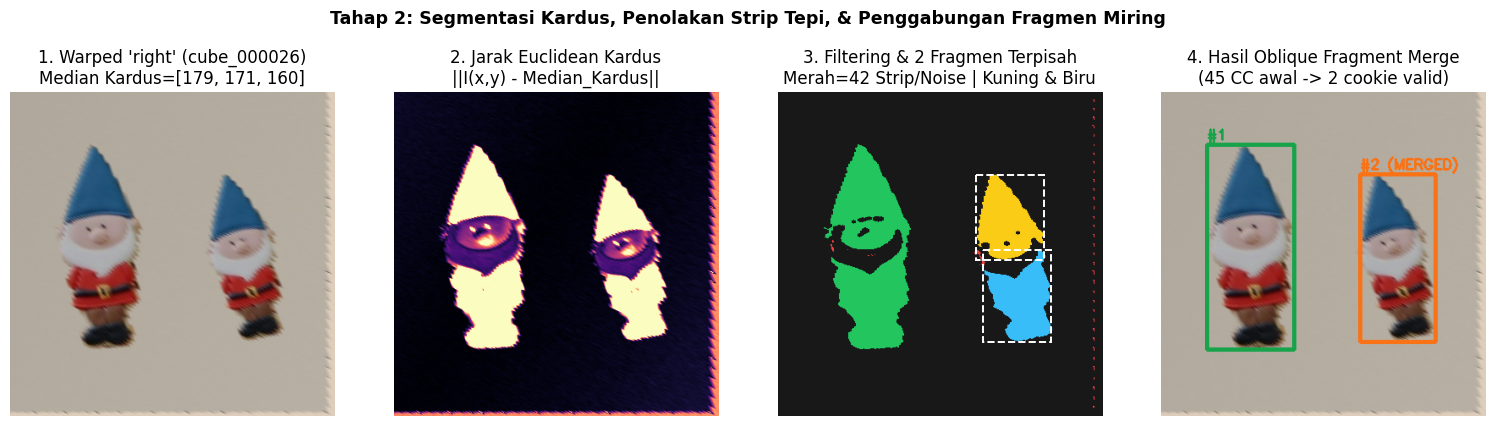

In [3]:
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    with Image.open(io.BytesIO(zf.read(annotations[26]["image"]))) as im:
        rgb26 = np.asarray(im.convert("RGB"))

_, dm26 = fit_background_model(rgb26)
hx26, _ = extract_cube_hexagon(rgb26, dist_map=dm26)
vc26, par26 = compute_vanishing_center(hx26, rgb=rgb26)
fq26 = segment_cube_faces(rgb26, hx26, vc26, parity=par26)
wf26_right, _ = rectify_face(rgb26, fq26["right"], CANONICAL_FACE_SIZE)

h26, w26 = wf26_right.shape[:2]
cmed26 = np.median(wf26_right[12:-12, 12:-12], axis=(0, 1)).astype(np.float32)
diff26 = np.linalg.norm(wf26_right.astype(np.float32) - cmed26, axis=2)
diff_vis26 = diff26.copy()
diff26[:10, :] = 0.0
diff26[-10:, :] = 0.0
diff26[:, :10] = 0.0
diff26[:, -10:] = 0.0
fg_raw26 = (diff26 > 22.0).astype(np.uint8)
fg_closed26 = cv2.morphologyEx(fg_raw26, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
hsv26 = cv2.cvtColor(wf26_right, cv2.COLOR_RGB2HSV)
rich26 = (hsv26[:, :, 1] > 42) | (hsv26[:, :, 2] < float(cmed26.mean()) - 28.0)

n_lbl26, lbl26, st26, cen26 = cv2.connectedComponentsWithStats(fg_closed26)
stage_map = np.full((h26, w26, 3), 24, dtype=np.uint8)
kept_raw = []
n_rejected = 0
for lbl in range(1, n_lbl26):
    m_lbl = lbl26 == lbl
    area = int(st26[lbl, cv2.CC_STAT_AREA])
    x, y, bw, bh = int(st26[lbl, 0]), int(st26[lbl, 1]), int(st26[lbl, 2]), int(st26[lbl, 3])
    ar_b = max(bw, bh) / max(1.0, float(min(bw, bh)))
    edge_t = (x <= 14) or (y <= 14) or (x + bw >= w26 - 14) or (y + bh >= h26 - 14)
    rr = float(np.mean(rich26[m_lbl]))
    is_rej = (area < 220) or (ar_b > 3.6) or (min(bw, bh) < 26) or (edge_t and ar_b > 2.9) or (rr < 0.22 and area < 1500)
    if is_rej:
        stage_map[m_lbl] = (239, 68, 68)  # Merah: noise / strip tepi rusuk ditolak
        n_rejected += 1
    else:
        c_dict = {"bbox": (x, y, bw, bh), "area": area, "mask_closed": m_lbl.astype(np.uint8)}
        kept_raw.append((lbl, c_dict))

# Tandai fragmen berukuran kecil/terbelah (kuning/biru) vs komponen besar utuh (hijau).
max_a26 = max(c["area"] for _, c in kept_raw)
frag_cols = [(250, 204, 21), (56, 189, 248), (249, 115, 22)]
frag_idx = 0
frag_boxes = []
for lbl, c in kept_raw:
    ar_r = _oriented_aspect_ratio(c["mask_closed"])
    is_frag = (c["area"] < 0.65 * max_a26) or (ar_r < 1.65)
    if is_frag:
        stage_map[lbl26 == lbl] = frag_cols[frag_idx % len(frag_cols)]
        frag_boxes.append(c["bbox"])
        frag_idx += 1
    else:
        stage_map[lbl26 == lbl] = (34, 197, 94)

final_comps26, _ = segment_face_cookies(wf26_right)
final_vis26 = wf26_right.copy()
for ci, comp in enumerate(final_comps26, start=1):
    x, y, bw, bh = comp["bbox"]
    col_box = (249, 115, 22) if comp.get("was_split", False) else (22, 163, 74)
    cv2.rectangle(final_vis26, (x, y), (x + bw, y + bh), col_box, 3)
    tag = f"#{ci} (MERGED)" if comp.get("was_split", False) else f"#{ci}"
    x_txt = max(6, min(x, w26 - 125))
    cv2.putText(final_vis26, tag, (x_txt, max(20, y - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, col_box, 2)

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.3))
axes[0].imshow(wf26_right)
axes[0].set_title(f"1. Warped 'right' (cube_000026)\nMedian Kardus={np.round(cmed26, 0).astype(int).tolist()}")

axes[1].imshow(diff_vis26, cmap="magma", vmin=0, vmax=80)
axes[1].set_title("2. Jarak Euclidean Kardus\n||I(x,y) - Median_Kardus||")

axes[2].imshow(stage_map)
for bx_f, by_f, bw_f, bh_f in frag_boxes:
    axes[2].add_patch(plt.Rectangle((bx_f, by_f), bw_f, bh_f, fill=False, edgecolor="white", ls="--", lw=1.4))
axes[2].set_title(f"3. Filtering & {len(frag_boxes)} Fragmen Terpisah\nMerah={n_rejected} Strip/Noise | Kuning & Biru")

axes[3].imshow(final_vis26)
axes[3].set_title(f"4. Hasil Oblique Fragment Merge\n({n_lbl26 - 1} CC awal -> {len(final_comps26)} cookie valid)")

for ax in axes:
    ax.axis("off")
plt.suptitle("Tahap 2: Segmentasi Kardus, Penolakan Strip Tepi, & Penggabungan Fragmen Miring", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(FIG_DIR / "task2_non_dl_segmentation_merge.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Tahap 3 — Multi-Template NCC & Anatomi Matematis Evaluasi Cacat Tri-Modal
Setiap instansi hasil segmentasi kami sejajarkan secara *coarse-to-fine* (`TM_CCOEFF_NORMED` skala `0.35x` diikuti penyempurnaan *fine* ber-mask) terhadap ketujuh referensi dan kami pilih memakai skor `design_score`. Setelah disejajarkan, kami mencocokkan pencahayaan template $T$ ke observasi $O$ memakai regresi affine kokoh per kanal RGB ($\hat{T} = g \cdot T + b$) lalu menghitung peta residu toleran-geser $3 \times 3$:
$$R_{\text{shift}}(x, y) = \min_{\Delta x, \Delta y \in \{-1,0,1\}} \left\| O(x, y) - \hat{T}(x + \Delta x, y + \Delta y) \right\|_2$$
Dari peta tersebut, kami memisahkan tiga mode cacat secara ortogonal (`miss_sil` biru, `hole_frac` kuning, dan `blob_frac` merah) dengan ambang keputusan $\max(\text{miss}/0.085,\ \text{hole}/0.055,\ \text{blob}/0.085) > 1.0$.

Sisi front -> 2 cookie:
  #1 desain=blue_wizard | ncc=0.942 | miss=0.000, hole=0.001, blob=0.029 -> ratio=0.34 (SEMPURNA)
  #2 desain=blue_wizard | ncc=0.830 | miss=0.000, hole=0.002, blob=0.492 -> ratio=5.78 (CACAT)
Sisi right -> 3 cookie:
  #1 desain=blue_wizard | ncc=0.777 | miss=0.001, hole=0.016, blob=0.444 -> ratio=5.22 (CACAT)
  #2 desain=blue_wizard | ncc=0.961 | miss=0.000, hole=0.001, blob=0.000 -> ratio=0.01 (SEMPURNA)
  #3 desain=blue_wizard | ncc=0.977 | miss=0.001, hole=0.000, blob=0.000 -> ratio=0.01 (SEMPURNA)
Sisi top   -> 1 cookie:
  #1 desain=blue_wizard | ncc=0.991 | miss=0.000, hole=0.000, blob=0.000 -> ratio=0.00 (SEMPURNA)


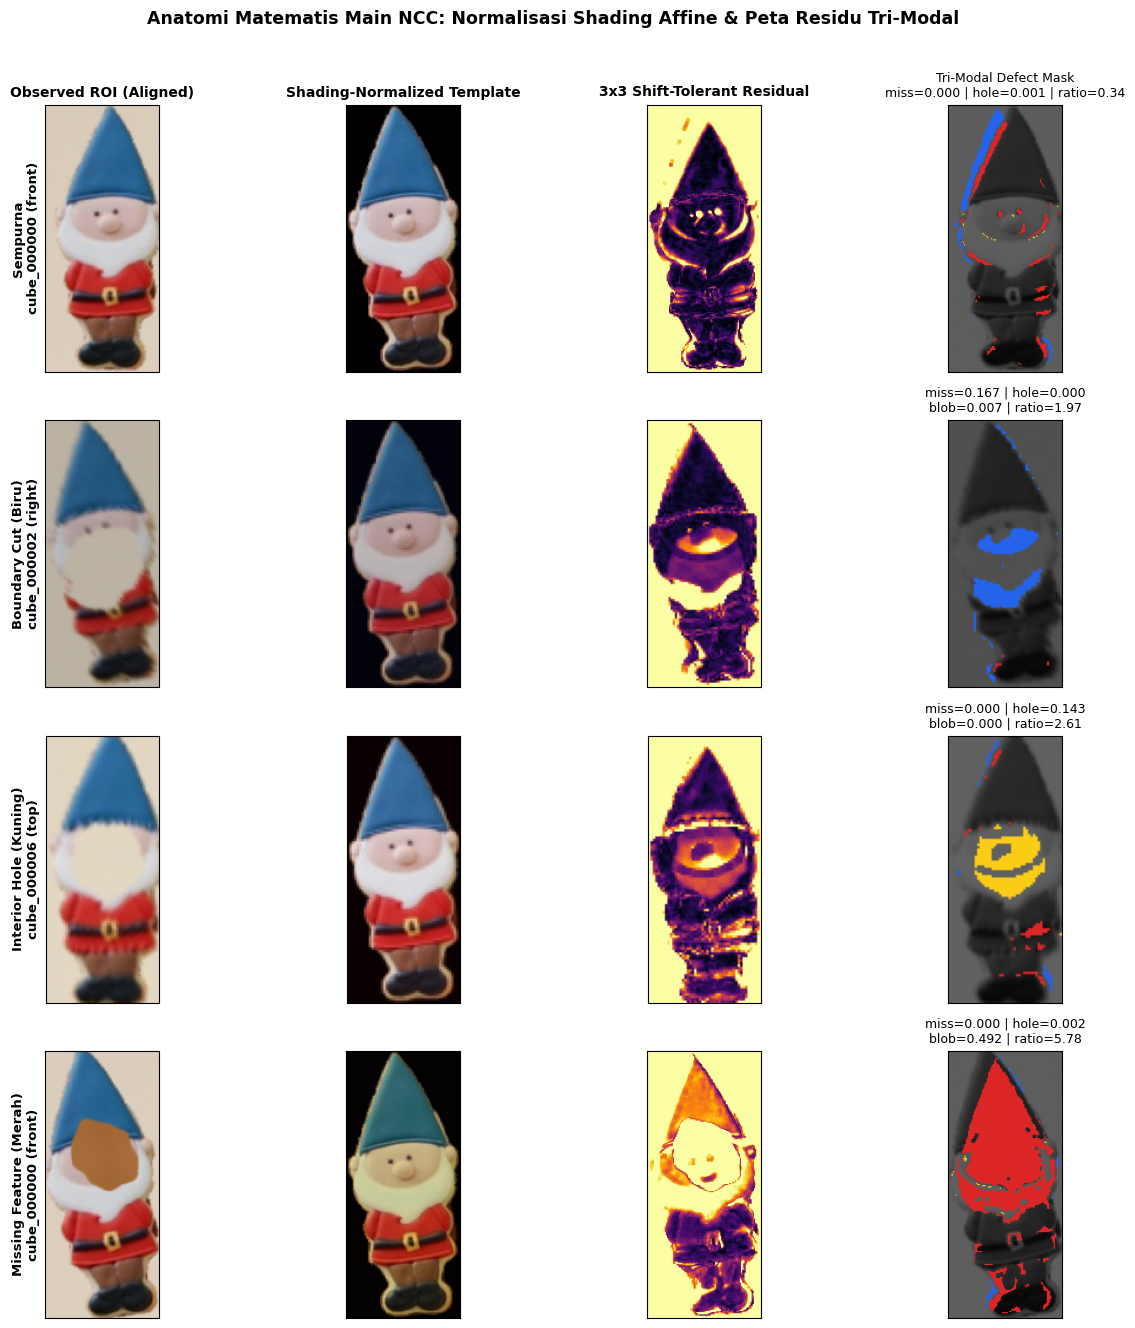

In [4]:
ref_cache = prepare_reference_cache(references)
ref0 = next(iter(ref_cache.values()))

for fn in FACES:
    w_face = warped_faces[fn]
    comps, card_med = segment_face_cookies(w_face)
    peer = (
        float(np.median([max(c["bbox"][2] / ref0["w"], c["bbox"][3] / ref0["h"]) for c in comps]))
        if len(comps) >= 2
        else None
    )
    print(f"Sisi {fn:5s} -> {len(comps)} cookie:")
    for idx_c, comp in enumerate(comps, start=1):
        sc = align_and_score_cookie(w_face, comp, ref_cache, card_med, peer_scale=peer)
        print(
            f"  #{idx_c} desain={ref_cache[sc['design_id']]['name']} | ncc={sc['ncc']:.3f} | "
            f"miss={sc['miss_sil']:.3f}, hole={sc['hole_frac']:.3f}, blob={sc['blob_frac']:.3f} "
            f"-> ratio={sc['defect_ratio']:.2f} ({'CACAT' if sc['is_defective'] else 'SEMPURNA'})"
        )


def inspect_aligned_cookie_maps(warped_face, comp, ref_cache, card_med, peer_scale=None):
    sc_out = align_and_score_cookie(warped_face, comp, ref_cache, card_med, peer_scale=peer_scale)
    r_entry = ref_cache[sc_out["design_id"]]
    theta, ar = _major_axis_angle_deg(comp["mask_solid"])
    base_angles = [theta, theta + 180.0] + ([0.0, 90.0, 180.0, -90.0] if ar < 1.48 else [])
    best_cand = None
    for ba in base_angles:
        for da in (-9.0, 0.0, 9.0):
            ang = ((ba + da + 180.0) % 360.0) - 180.0
            rc = _rotate_crop_patch(warped_face, comp, ang, card_med)
            if rc is None:
                continue
            rot_img, _, _, bbox = rc
            est_s = max(bbox[2] / max(1.0, float(r_entry["w"])), bbox[3] / max(1.0, float(r_entry["h"])))
            scales = [0.92 * est_s, est_s, 1.10 * est_s] + ([peer_scale] if peer_scale is not None else [])
            for sc_val in scales:
                sc_c = float(np.clip(sc_val, 0.25, 1.40))
                ch = _match_template_coarse(rot_img, bbox, r_entry, sc_c, card_med, coarse_factor=0.35)
                if ch is None:
                    continue
                fh = _match_template_fine(rot_img, r_entry, sc_c, (ch[1], ch[2]), card_med, search_rad=8)
                if fh is not None and (best_cand is None or fh[0] > best_cand["ncc"]):
                    best_cand = {"did": sc_out["design_id"], "ncc": fh[0], "ang": ang, "sc": sc_c, "gx": fh[1], "gy": fh[2], "rc": rc}
    st = _extract_aligned_design_stats(best_cand, r_entry, card_med)
    obs, tmpl_rgb, tmpl_m = st["obs_crop"], st["tmpl_rgb"], st["tmpl_mask"]
    solid_b, raw_b, solid_c = st["solid_bool"], st["raw_bool"], st["solid_crop"]
    intact = tmpl_m & raw_b
    gains, biases = _fit_shading_affine(obs[intact], tmpl_rgb[intact])
    norm_t = tmpl_rgb * gains + biases
    th, tw = st["th"], st["tw"]
    pad_nt = np.pad(norm_t, ((1, 1), (1, 1), (0, 0)), mode="edge")
    rsh = np.full((th, tw), 1e6, dtype=np.float32)
    for sy in range(3):
        for sx in range(3):
            rsh = np.minimum(rsh, np.linalg.norm(obs - pad_nt[sy : sy + th, sx : sx + tw], axis=2))

    miss_m = tmpl_m & ~solid_b & (rsh > 19.0)
    solid_er = cv2.erode(solid_c, np.ones((3, 3), np.uint8), iterations=1) > 0
    if comp.get("was_split", False):
        cnts_s, _ = cv2.findContours(solid_c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        hm = np.zeros_like(solid_c)
        if cnts_s:
            cv2.drawContours(hm, [cv2.convexHull(np.vstack(cnts_s))], -1, 1, thickness=-1)
        hole_reg = solid_er | (cv2.erode(hm, np.ones((5, 5), np.uint8), iterations=1) > 0)
    else:
        hole_reg = solid_er
    hole_m = hole_reg & (np.linalg.norm(obs - card_med, axis=2) < 15.0) & (rsh > 19.0)
    blob_m = cv2.erode((intact & (rsh > 18.0)).astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1) > 0

    gray_bg = np.repeat(cv2.cvtColor(np.clip(obs, 0, 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)[:, :, None], 3, axis=2)
    mask_vis = (0.45 * gray_bg).astype(np.uint8)
    mask_vis[miss_m] = (37, 99, 235)
    mask_vis[hole_m] = (250, 204, 21)
    mask_vis[blob_m] = (220, 38, 38)
    return {"obs": np.clip(obs, 0, 255).astype(np.uint8), "norm_t": np.clip(norm_t, 0, 255).astype(np.uint8), "rsh": rsh, "mask_vis": mask_vis, "sc": sc_out}


defect_samples = {}
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    for ann in annotations[:75]:
        with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
            rgb_i = np.asarray(im.convert("RGB"))
        _, dm_i = fit_background_model(rgb_i)
        hx_i, _ = extract_cube_hexagon(rgb_i, dist_map=dm_i)
        vc_i, par_i = compute_vanishing_center(hx_i, rgb=rgb_i)
        fq_i = segment_cube_faces(rgb_i, hx_i, vc_i, parity=par_i)
        for fn in FACES:
            wf_i, _ = rectify_face(rgb_i, fq_i[fn], CANONICAL_FACE_SIZE)
            cs_i, cm_i = segment_face_cookies(wf_i)
            pr_i = float(np.median([max(c["bbox"][2] / ref0["w"], c["bbox"][3] / ref0["h"]) for c in cs_i])) if len(cs_i) >= 2 else None
            for c_i in cs_i:
                sc_i = align_and_score_cookie(wf_i, c_i, ref_cache, cm_i, peer_scale=pr_i)
                cat = None
                if not sc_i["is_defective"] and sc_i["defect_ratio"] < 0.35 and "perfect" not in defect_samples:
                    cat = "perfect"
                elif sc_i["miss_sil"] > 0.14 and "boundary_cut" not in defect_samples:
                    cat = "boundary_cut"
                elif sc_i["hole_frac"] > 0.08 and "interior_hole" not in defect_samples:
                    cat = "interior_hole"
                elif sc_i["blob_frac"] > 0.15 and "missing_feature" not in defect_samples:
                    cat = "missing_feature"
                if cat is not None:
                    defect_samples[cat] = inspect_aligned_cookie_maps(wf_i, c_i, ref_cache, cm_i, peer_scale=pr_i)
                    defect_samples[cat]["tag"] = f"{Path(ann['image']).stem} ({fn})"
        if len(defect_samples) == 4:
            break

fig, axes = plt.subplots(4, 4, figsize=(13.5, 13.5))
col_titles = ["Observed ROI (Aligned)", "Shading-Normalized Template", "3x3 Shift-Tolerant Residual", "Tri-Modal Defect Mask"]
row_meta = [
    ("perfect", "Sempurna"),
    ("boundary_cut", "Boundary Cut (Biru)"),
    ("interior_hole", "Interior Hole (Kuning)"),
    ("missing_feature", "Missing Feature (Merah)"),
]
for r_i, (k_cat, r_lbl) in enumerate(row_meta):
    item = defect_samples[k_cat]
    sc_v = item["sc"]
    axes[r_i, 0].imshow(item["obs"])
    axes[r_i, 1].imshow(item["norm_t"])
    axes[r_i, 2].imshow(item["rsh"], cmap="inferno", vmin=0, vmax=50)
    axes[r_i, 3].imshow(item["mask_vis"])
    axes[r_i, 0].set_ylabel(f"{r_lbl}\n{item['tag']}", fontsize=9.5, fontweight="bold")
    axes[r_i, 3].set_title(
        f"miss={sc_v['miss_sil']:.3f} | hole={sc_v['hole_frac']:.3f}\nblob={sc_v['blob_frac']:.3f} | ratio={sc_v['defect_ratio']:.2f}",
        fontsize=9,
    )
    if r_i == 0:
        for c_j in range(3):
            axes[0, c_j].set_title(col_titles[c_j], fontsize=10, fontweight="bold")
        axes[0, 3].set_title(f"{col_titles[3]}\nmiss={sc_v['miss_sil']:.3f} | hole={sc_v['hole_frac']:.3f} | ratio={sc_v['defect_ratio']:.2f}", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Anatomi Matematis Main NCC: Normalisasi Shading Affine & Peta Residu Tri-Modal", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(FIG_DIR / "task2_non_dl_tri_modal_anatomy.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Studi Generalisasi Desain `1-Referensi` vs `7-Referensi` (`template_all`)
Seluruh `100` citra kubus pada arsip pelatihan hanya memakai desain tunggal (`blue_wizard`), sedangkan `200` citra *hidden* memadukan ketujuh desain. Di bawah ini kami membuktikan komposisi desain arsip pelatihan secara terprogram, lalu membandingkan langsung hasil `1-ref` vs `7-ref` pada citra multi-desain nyata di *hidden test* (`cube_0817258b17ffb7d2`).

In [5]:
train_designs = sorted({int(k) for ann in annotations for f in ann["faces"] for k in f["counts_by_design"]})
print(f"Desain unik pada 100 citra training berlabel: {[references[d]['name'] for d in train_designs]}")

# Bangun cache 1-referensi (hanya blue_wizard) tanpa auto-augmentasi template_all.
ref1_raw = references[1]["rgba"]
hw1, hh1 = max(32, ref1_raw.shape[1] // 2), max(32, ref1_raw.shape[0] // 2)
tight1 = _crop_tight_rgba(cv2.resize(ref1_raw, (hw1, hh1), interpolation=cv2.INTER_AREA), pad=3)
m1 = (tight1[:, :, 3] > 128).astype(np.uint8)
m1_in = cv2.erode(m1, np.ones((3, 3), np.uint8), iterations=1)
ref_cache_1 = {
    1: {
        "name": references[1]["name"],
        "rgb": tight1[:, :, :3].astype(np.float32),
        "mask": m1,
        "mask_inner": m1_in if int(m1_in.sum()) >= 50 else m1,
        "h": tight1.shape[0],
        "w": tight1.shape[1],
        "coarse_cache": {},
        "fine_cache": {},
    }
}

# Uji perbandingan 1-ref vs 7-ref pada sampel hidden nyata yang memuat desain non-blue_wizard.
with zipfile.ZipFile(HIDDEN_ZIP) as zf:
    hidden_test_df = pd.read_csv(io.BytesIO(zf.read("test_cube.csv")), dtype={"image_id": str})
    hidden_path_map = dict(zip(hidden_test_df["image_id"], hidden_test_df["image"]))
    target_hid = "cube_0817258b17ffb7d2" if "cube_0817258b17ffb7d2" in hidden_path_map else hidden_test_df["image_id"].iloc[0]
    with Image.open(io.BytesIO(zf.read(hidden_path_map[target_hid]))) as im:
        hid_rgb = np.asarray(im.convert("RGB"))

_, dm_h = fit_background_model(hid_rgb)
hx_h, _ = extract_cube_hexagon(hid_rgb, dist_map=dm_h)
vc_h, par_h = compute_vanishing_center(hx_h, rgb=hid_rgb)
fq_h = segment_cube_faces(hid_rgb, hx_h, vc_h, parity=par_h)

gen_rows = []
for fn in FACES:
    wf_h, _ = rectify_face(hid_rgb, fq_h[fn], CANONICAL_FACE_SIZE)
    cs_h, cm_h = segment_face_cookies(wf_h)
    for ci, c_h in enumerate(cs_h, start=1):
        s1 = align_and_score_cookie(wf_h, c_h, ref_cache_1, cm_h)
        s7 = align_and_score_cookie(wf_h, c_h, ref_cache, cm_h)
        gen_rows.append(
            {
                "sisi": fn,
                "cookie": ci,
                "1-ref match": references[1]["name"],
                "1-ref NCC": round(s1["ncc"], 3),
                "1-ref ratio": round(s1["defect_ratio"], 2),
                "7-ref match": ref_cache[s7["design_id"]]["name"],
                "7-ref NCC": round(s7["ncc"], 3),
                "7-ref ratio": round(s7["defect_ratio"], 2),
                "7-ref status": "CACAT" if s7["is_defective"] else "SEMPURNA",
            }
        )

print(f"Perbandingan Generalisasi 1-Ref vs 7-Ref pada Sampel Hidden '{target_hid}':")
display(pd.DataFrame(gen_rows))
print("Rekam Jejak Evaluasi Leaderboard:")
print("  - Training 100 citra (desain tunggal blue_wizard): 1-ref = 100.0%, 7-ref = 100.0%")
print("  - Kaggle Hidden 200 citra (7 desain campuran)     : 1-ref (submission_task2.csv) = 0.08333 -> 7-ref (task2_ncc_lb.csv) = 0.00000")

Desain unik pada 100 citra training berlabel: ['blue_wizard']
Perbandingan Generalisasi 1-Ref vs 7-Ref pada Sampel Hidden 'cube_0817258b17ffb7d2':


,sisi,cookie,1-ref match,1-ref NCC,1-ref ratio,7-ref match,7-ref NCC,7-ref ratio,7-ref status
0,front,1,blue_wizard,0.590,0.03,santa,0.978,0.00,SEMPURNA
1,front,2,blue_wizard,0.386,0.00,witch,0.890,0.01,SEMPURNA
2,right,1,blue_wizard,0.352,0.13,striped_hat_elf,0.956,0.03,SEMPURNA
3,top,1,blue_wizard,0.543,4.40,pilgrim,0.650,4.01,CACAT
4,top,2,blue_wizard,0.452,0.00,brown_hat_gnome,0.920,0.00,SEMPURNA
5,top,3,blue_wizard,0.544,0.00,green_hat_elf,0.931,2.69,CACAT


Rekam Jejak Evaluasi Leaderboard:
  - Training 100 citra (desain tunggal blue_wizard): 1-ref = 100.0%, 7-ref = 100.0%
  - Kaggle Hidden 200 citra (7 desain campuran)     : 1-ref (submission_task2.csv) = 0.08333 -> 7-ref (task2_ncc_lb.csv) = 0.00000


### 6. Evaluasi Menyeluruh `Main NCC` (`100` Kubus) & Inferensi *Hidden Test* (`200` Citra)
Kami mengeksekusi `predict_cube_non_dl` pada seluruh `100` citra berlabel, melaporkan seluruh metrik standar termasuk **`MAE_def_on_def_faces`** (kinerja khusus sisi yang memiliki cacat) serta **`MAE` per sisi** (`front`, `right`, `top`) untuk ketiga target, lalu memvalidasi ekspor `task2_ncc_lb.csv` (10 kolom) dan `task2_ncc_main.csv` (7 kolom).

In [6]:
pred_rows = []
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    t0 = time.time()
    for ann in annotations:
        img_id = Path(ann["image"]).stem
        with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
            rgb = np.asarray(im.convert("RGB"))
        pred_rows.append({"image_id": img_id, **predict_cube_non_dl(rgb, references, leaderboard=True)})
    elapsed_train = time.time() - t0

df_pred = pd.DataFrame(pred_rows, columns=cube_columns(True))
validate_cube_predictions(df_pred, df_truth.image_id.tolist(), len(references), leaderboard=True)


def summarize_by_split(df_model: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    rows_s = []
    per_face_all = {}
    for sp in ("train", "val", "test", "all"):
        sub_t = df_truth if sp == "all" else df_truth[df_truth["split"] == sp]
        sub_p = df_model if sp == "all" else df_model[df_model["image_id"].isin(set(sub_t["image_id"]))]
        m_main = evaluate_cube_dataframe(sub_p[cube_columns(False)], sub_t, leaderboard=False)
        m_lb = evaluate_cube_dataframe(sub_p, sub_t, leaderboard=True)
        if sp == "all":
            per_face_all = {
                fn: {
                    "MAE_total": m_lb[f"mae_{fn}_total"],
                    "MAE_defective": m_lb[f"mae_{fn}_defective"],
                    "MAE_design_count": m_lb[f"mae_{fn}_design_count"],
                }
                for fn in FACES
            }
        rows_s.append(
            {
                "split": sp,
                "n_cubes": len(sub_p),
                "MAE_total": m_main["mae_total"],
                "MAE_defective": m_main["mae_defective"],
                "MAE_def_on_def_faces": m_main["mae_defective_on_defective_faces"],
                "MAE_design_count": m_lb["mae_design_count"],
                "ExactMatch_Face_%": m_main["exact_match_face_pct"],
                "ExactMatch_Main_%": m_main["exact_match_image_pct"],
                "ExactMatch_LB_%": m_lb["exact_match_image_pct"],
            }
        )
    return pd.DataFrame(rows_s), per_face_all


df_main_summary, main_per_face = summarize_by_split(df_pred)
print(f"Waktu inferensi 100 citra Main NCC: {elapsed_train:.2f}s ({elapsed_train/len(df_pred):.3f}s/citra)")
display(df_main_summary)

sub_lb_path = ROOT / "submissions" / "task2_ncc_lb.csv"
sub_main_path = ROOT / "submissions" / "task2_ncc_main.csv"
FORCE_REGEN_MAIN = True  # Ubah ke False jika ingin melewati inferensi ulang 200 citra dan memakai cache CSV.

with zipfile.ZipFile(HIDDEN_ZIP) as zf:
    sample_ids = pd.read_csv(io.BytesIO(zf.read("sample_submission_task2.csv")), dtype={"image_id": str})["image_id"].tolist()
    test_df_h = pd.read_csv(io.BytesIO(zf.read("test_cube.csv")), dtype={"image_id": str})
    path_map = dict(zip(test_df_h["image_id"], test_df_h["image"]))

    if FORCE_REGEN_MAIN or not (sub_lb_path.exists() and sub_main_path.exists()):
        t0 = time.time()
        rows_main = []
        for img_id in sample_ids:
            with Image.open(io.BytesIO(zf.read(path_map[img_id]))) as im:
                rgb = np.asarray(im.convert("RGB"))
            rows_main.append({"image_id": img_id, **predict_cube_non_dl(rgb, references, leaderboard=True)})
        elapsed_h_main = time.time() - t0
        df_hidden_main = pd.DataFrame(rows_main, columns=cube_columns(True))
        df_hidden_main_7 = df_hidden_main[cube_columns(False)].copy()
        df_hidden_main.to_csv(sub_lb_path, index=False)
        df_hidden_main_7.to_csv(sub_main_path, index=False)
        print(f"[Main NCC] Hidden 200 citra selesai dalam {elapsed_h_main:.2f}s ({elapsed_h_main/len(sample_ids):.3f}s/img).")
    else:
        df_hidden_main = pd.read_csv(sub_lb_path, dtype={"image_id": str})
        df_hidden_main_7 = pd.read_csv(sub_main_path, dtype={"image_id": str})

validate_cube_predictions(df_hidden_main, sample_ids, len(references), leaderboard=True)
validate_cube_predictions(df_hidden_main_7, sample_ids, len(references), leaderboard=False)
print(f"Validasi CSV utama OK -> {sub_lb_path.name} ({df_hidden_main.shape}) & {sub_main_path.name} ({df_hidden_main_7.shape})")
display(df_hidden_main.head(5))

Waktu inferensi 100 citra Main NCC: 204.28s (2.043s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_def_on_def_faces,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,train,70,0.0,0.0,0.0,0.0,100.0,100.0,100.0
1,val,15,0.0,0.0,0.0,0.0,100.0,100.0,100.0
2,test,15,0.0,0.0,0.0,0.0,100.0,100.0,100.0
3,all,100,0.0,0.0,0.0,0.0,100.0,100.0,100.0


[Main NCC] Hidden 200 citra selesai dalam 428.28s (2.141s/img).
Validasi CSV utama OK -> task2_ncc_lb.csv ((200, 10)) & task2_ncc_main.csv ((200, 7))


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3
3,cube_0a759e86474d3700,1,1,1,0,0,0,1,1,1
4,cube_0ad969fcad819b22,2,3,2,0,0,0,2,2,2


### 7. Kerangka Pembanding & Visualisasi *Two-Stage Pose Fitting* (`SIFT` vs `ORB`)
Ketiga model pembanding menggunakan *front-end* geometri 3D dan segmentasi cookie yang identik agar evaluasi murni mengukur kualitas pengenalan desain serta inspeksi cacat. Untuk `SIFT + RANSAC` dan `ORB + RANSAC`, visualisasi berikut menunjukkan korespondensi *inlier* RANSAC (kuning) vs *tight inliers* pasca-*refit* analitik SVD Umeyama ($e \le 2.2\text{ px}$, hijau) beserta kontur siluet dan peta residu `3x3`.

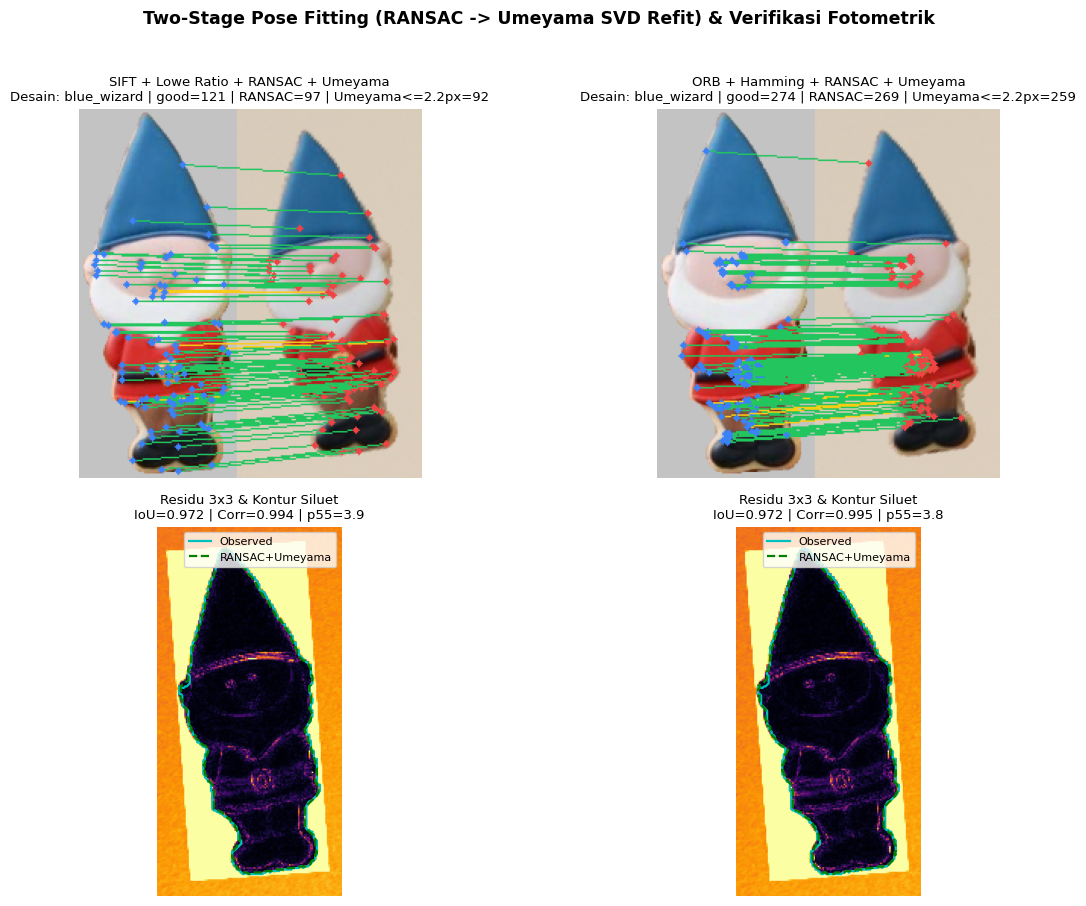

In [7]:
MODEL_BENCHMARKS = {
    "main_ncc": {
        "label": "Main Multi-Template NCC",
        "elapsed_train_s": float(elapsed_train),
        "sec_per_img": float(elapsed_train / len(df_pred)),
        "summary_df": df_main_summary,
        "per_face_all": main_per_face,
        "pred_train_df": df_pred.copy(),
    }
}
HIDDEN_LB_DFS = {"main_ncc": df_hidden_main.copy()}


def evaluate_and_record_model(model_key: str, model_label: str, predict_fn) -> pd.DataFrame:
    rows = []
    with zipfile.ZipFile(TRAIN_ZIP) as zf:
        t0 = time.time()
        for ann in annotations:
            img_id = Path(ann["image"]).stem
            with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
                rgb = np.asarray(im.convert("RGB"))
            rows.append({"image_id": img_id, **predict_fn(rgb, references, leaderboard=True)})
        elapsed_s = time.time() - t0

    df_m = pd.DataFrame(rows, columns=cube_columns(True))
    validate_cube_predictions(df_m, df_truth.image_id.tolist(), len(references), leaderboard=True)
    sp_df, pf_all = summarize_by_split(df_m)
    MODEL_BENCHMARKS[model_key] = {
        "label": model_label,
        "elapsed_train_s": float(elapsed_s),
        "sec_per_img": float(elapsed_s / len(df_m)),
        "summary_df": sp_df,
        "per_face_all": pf_all,
        "pred_train_df": df_m,
    }
    print(f"[{model_label}] 100 citra selesai dalam {elapsed_s:.2f}s ({elapsed_s / len(df_m):.3f}s/citra)")
    return sp_df


def export_hidden_submission(model_key: str, predict_fn, out_prefix: str) -> pd.DataFrame:
    lb_path = ROOT / "submissions" / f"{out_prefix}_lb.csv"
    main_path = ROOT / "submissions" / f"{out_prefix}_main.csv"
    rows = []
    with zipfile.ZipFile(HIDDEN_ZIP) as zf:
        t0 = time.time()
        for img_id in sample_ids:
            with Image.open(io.BytesIO(zf.read(path_map[img_id]))) as im:
                rgb = np.asarray(im.convert("RGB"))
            rows.append({"image_id": img_id, **predict_fn(rgb, references, leaderboard=True)})
        elapsed_h = time.time() - t0

    df_lb = pd.DataFrame(rows, columns=cube_columns(True))
    df_main = df_lb[cube_columns(False)].copy()
    validate_cube_predictions(df_lb, sample_ids, len(references), leaderboard=True)
    validate_cube_predictions(df_main, sample_ids, len(references), leaderboard=False)
    df_lb.to_csv(lb_path, index=False)
    df_main.to_csv(main_path, index=False)
    HIDDEN_LB_DFS[model_key] = df_lb
    tot_def = df_lb[[f"{f}_defective" for f in FACES]].sum(axis=1)
    print(f"[{model_key}] Hidden 200 selesai dalam {elapsed_h:.2f}s ({elapsed_h / len(df_lb):.3f}s/citra) -> dist cacat {tot_def.value_counts().sort_index().to_dict()}")
    return df_lb


front_face = warped_faces["front"]
front_comps, front_cmed = segment_face_cookies(front_face)


def _solve_keypoint_vis_sample(roi_rgb, roi_solid, roi_raw, bw, bh, cmed, method):
    rc_feat = _prepare_feature_refs(references, method=method)
    det, matcher, r_thr, rp_thr, target_px = _build_feature_config(method)
    rh_o, rw_o = roi_rgb.shape[:2]
    roi_solid_bool = roi_solid > 0
    roi_raw_bool = roi_raw > 0
    roi_f = roi_rgb.astype(np.float32)
    up = float(np.clip(target_px / max(1.0, float(max(bw, bh))), 2.0, 3.6))
    up_w, up_h = int(round(rw_o * up)), int(round(rh_o * up))
    roi_up_gray = cv2.cvtColor(cv2.resize(roi_rgb, (up_w, up_h), interpolation=cv2.INTER_CUBIC), cv2.COLOR_RGB2GRAY)
    roi_up_mask = cv2.dilate(cv2.resize(roi_solid, (up_w, up_h), interpolation=cv2.INTER_NEAREST), np.ones((7, 7), np.uint8), iterations=1) * 255
    kps_obs, des_obs = det.detectAndCompute(roi_up_gray, roi_up_mask)
    if des_obs is None or len(kps_obs) < 4:
        return None
    obs_pts = np.float32([kp.pt for kp in kps_obs]) / up
    best_vis, best_sc = None, -1e9
    for _, re in rc_feat.items():
        if re["des"] is None or len(re["des"]) < 4:
            continue
        knn = matcher.knnMatch(re["des"], des_obs, k=2)
        good = [m for pair in knn if len(pair) == 2 for m, n in [pair] if m.distance < r_thr * n.distance]
        if len(good) < 4:
            continue
        src_p = np.float32([re["kps_pts"][m.queryIdx] for m in good])
        dst_p = np.float32([obs_pts[m.trainIdx] for m in good])
        M0, inl = cv2.estimateAffinePartial2D(src_p, dst_p, method=cv2.RANSAC, ransacReprojThreshold=rp_thr, maxIters=1200, confidence=0.995, refineIters=15)
        if M0 is None or inl is None or int(inl.sum()) < 4:
            continue
        sc_est = float(np.hypot(M0[0, 0], M0[0, 1]))
        if not (0.18 <= sc_est <= 0.90):
            continue
        errs0 = np.linalg.norm((src_p @ M0[:, :2].T) + M0[:, 2] - dst_p, axis=1)
        tight = errs0 <= 2.2
        M_fin = _umeyama_2d_similarity(src_p[tight], dst_p[tight]) if int(tight.sum()) >= 5 else None
        if M_fin is None:
            M_fin = M0
        inl_fin = np.linalg.norm((src_p @ M_fin[:, :2].T) + M_fin[:, 2] - dst_p, axis=1) <= rp_thr
        mw = cv2.warpAffine(re["mask"], M_fin, (rw_o, rh_o), flags=cv2.INTER_NEAREST, borderValue=0) > 0
        iou = float(np.sum(mw & roi_solid_bool)) / float(max(1, int(np.sum(mw | roi_solid_bool))))
        if iou < 0.35:
            continue
        tw = cv2.warpAffine(re["rgb"], M_fin, (rw_o, rh_o), flags=cv2.INTER_LINEAR, borderValue=tuple(float(v) for v in cmed))
        mw_er = cv2.erode(mw.astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1) > 0
        intact = mw_er & roi_raw_bool
        corr, p55 = 0.0, 90.0
        rsh = np.zeros((rh_o, rw_o), dtype=np.float32)
        if int(intact.sum()) >= 60:
            gs, bs = _fit_shading_affine(roi_f[intact], tw[intact])
            nt = tw * gs + bs
            p55 = float(np.percentile(np.linalg.norm(roi_f[intact] - nt[intact], axis=1), 55))
            ov = roi_f[intact] - roi_f[intact].mean(axis=0, keepdims=True)
            tv = tw[intact] - tw[intact].mean(axis=0, keepdims=True)
            corr = float(np.sum(ov * tv) / (np.sqrt(np.sum(ov * ov) * np.sum(tv * tv)) + 1e-6))
            pnt = np.pad(nt, ((1, 1), (1, 1), (0, 0)), mode="edge")
            rsh.fill(1e6)
            for sy in range(3):
                for sx in range(3):
                    rsh = np.minimum(rsh, np.linalg.norm(roi_f - pnt[sy : sy + rh_o, sx : sx + rw_o], axis=2))
        sc_hyp = 0.60 * corr + 0.35 * iou + 0.22 * min(int(inl_fin.sum()), 35) / 35.0 - 0.010 * p55
        if sc_hyp > best_sc:
            best_sc = sc_hyp
            best_vis = (re, M0, M_fin, inl_fin, tight, good, src_p, dst_p, errs0, iou, corr, p55, rsh, mw)
    return best_vis


sample_pack = None
for fn_alt in FACES:
    wf_alt = warped_faces[fn_alt]
    cs_alt, cm_alt = segment_face_cookies(wf_alt)
    for cand_c in cs_alt:
        bx, by, bw, bh = cand_c["bbox"]
        pad = 14
        x0, y0 = max(0, bx - pad), max(0, by - pad)
        x1, y1 = min(wf_alt.shape[1], bx + bw + pad), min(wf_alt.shape[0], by + bh + pad)
        r_rgb, r_sol, r_raw = wf_alt[y0:y1, x0:x1], cand_c["mask_solid"][y0:y1, x0:x1], cand_c["mask_raw"][y0:y1, x0:x1]
        v_s = _solve_keypoint_vis_sample(r_rgb, r_sol, r_raw, bw, bh, cm_alt, "sift")
        v_o = _solve_keypoint_vis_sample(r_rgb, r_sol, r_raw, bw, bh, cm_alt, "orb")
        if v_s is not None and v_o is not None:
            sample_pack = (r_rgb, r_sol, {"sift": v_s, "orb": v_o})
            break
    if sample_pack is not None:
        break

roi_rgb_vis, roi_sol_vis, vis_by_method = sample_pack
rh_o, rw_o = roi_rgb_vis.shape[:2]

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))
for col_i, (method, title_lbl) in enumerate([("sift", "SIFT + Lowe Ratio + RANSAC + Umeyama"), ("orb", "ORB + Hamming + RANSAC + Umeyama")]):
    re_win, M0_w, M_fin, inl_fin, tight_m, good_m, src_p, dst_p, _, iou, corr, p55, rsh, mw_b = vis_by_method[method]
    ref_u8 = np.clip(re_win["rgb"], 0, 255).astype(np.uint8)
    scale_panel = rh_o / float(ref_u8.shape[0])
    ref_disp = cv2.resize(ref_u8, (max(1, int(round(ref_u8.shape[1] * scale_panel))), rh_o), interpolation=cv2.INTER_AREA)
    canvas = np.ascontiguousarray(np.hstack([ref_disp, roi_rgb_vis.copy()]))
    ox = ref_disp.shape[1]

    for f_inl, f_tight, p_ref, p_obs in zip(inl_fin, tight_m, src_p, dst_p):
        if f_inl:
            pt1 = (int(round(p_ref[0] * scale_panel)), int(round(p_ref[1] * scale_panel)))
            pt2 = (int(round(p_obs[0] + ox)), int(round(p_obs[1])))
            cv2.line(canvas, pt1, pt2, (34, 197, 94) if f_tight else (250, 204, 21), 1)
            cv2.circle(canvas, pt1, 2, (59, 130, 246), -1)
            cv2.circle(canvas, pt2, 2, (239, 68, 68), -1)

    axes[0, col_i].imshow(canvas)
    axes[0, col_i].set_title(
        f"{title_lbl}\nDesain: {re_win['name']} | good={len(good_m)} | RANSAC={int(inl_fin.sum())} | Umeyama<=2.2px={int(tight_m.sum())}",
        fontsize=9.5,
    )
    axes[1, col_i].imshow(rsh, cmap="inferno", vmin=0, vmax=50)
    cnt_obs, _ = cv2.findContours(roi_sol_vis.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt_wrp, _ = cv2.findContours(mw_b.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for ci_o, c_o in enumerate(cnt_obs):
        po = c_o.reshape(-1, 2)
        axes[1, col_i].plot(np.r_[po[:, 0], po[0, 0]], np.r_[po[:, 1], po[0, 1]], "c-", lw=1.6, label="Observed" if ci_o == 0 else None)
    for ci_w, c_w in enumerate(cnt_wrp):
        pw = c_w.reshape(-1, 2)
        axes[1, col_i].plot(np.r_[pw[:, 0], pw[0, 0]], np.r_[pw[:, 1], pw[0, 1]], "g--", lw=1.6, label="RANSAC+Umeyama" if ci_w == 0 else None)
    axes[1, col_i].set_title(f"Residu 3x3 & Kontur Siluet\nIoU={iou:.3f} | Corr={corr:.3f} | p55={p55:.1f}", fontsize=9.5)
    axes[1, col_i].legend(loc="upper right", fontsize=8, framealpha=0.8)

for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Two-Stage Pose Fitting (RANSAC -> Umeyama SVD Refit) & Verifikasi Fotometrik", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIG_DIR / "task2_non_dl_keypoint_umeyama.png", dpi=150, bbox_inches="tight")
plt.show()

### 8. Model Tambahan 1 — SIFT (`NORM_L2` + Lowe `0.82`) + RANSAC & Umeyama Refit
Kami mengekstraksi fitur float SIFT 128-D (`nfeatures=850`, `contrastThreshold=0.012`, `edgeThreshold=16`) pada ROI ter-*upscale* adaptif (`target 380 px`), menyaring kandidat `NORM_L2` memakai Lowe ratio `0.82`, melakukan RANSAC (`reproj=4.8 px`) diikuti *refit* analitik SVD Umeyama pada *tight inliers* ($e \le 2.2\text{ px}$), verifikasi fotometrik top-3, serta *fallback* ke `Contour + HSV` saat pose lemah.

In [8]:
df_sift_eval = evaluate_and_record_model("sift_ransac", "SIFT + RANSAC", predict_cube_sift_ransac)
display(df_sift_eval)
df_hidden_sift = export_hidden_submission("sift_ransac", predict_cube_sift_ransac, "task2_sift")
display(df_hidden_sift.head(3))

[SIFT + RANSAC] 100 citra selesai dalam 63.31s (0.633s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_def_on_def_faces,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,train,70,0.0,0.004762,0.014085,0.004762,99.523810,98.571429,97.142857
1,val,15,0.0,0.000000,0.000000,0.000000,100.000000,100.000000,100.000000
2,test,15,0.0,0.000000,0.000000,0.000000,100.000000,100.000000,100.000000
3,all,100,0.0,0.003333,0.009804,0.003333,99.666667,99.000000,98.000000


[sift_ransac] Hidden 200 selesai dalam 133.64s (0.668s/citra) -> dist cacat {0: 43, 1: 75, 2: 82}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3


### 9. Model Tambahan 2 — ORB Binary (`NORM_HAMMING` + Lowe `0.82`) + RANSAC & Umeyama Refit
Kami mengekstraksi fitur biner FAST+BRIEF memakai `cv2.ORB_create` (`nfeatures=950`, `fastThreshold=5`, `scaleFactor=1.12`, `nlevels=10`) pada ROI `320 px`, mencocokkannya dengan jarak bitwise `NORM_HAMMING`, lalu menerapkan alur *refit* Umeyama SVD dan verifikasi fotometrik yang konsisten.

In [9]:
df_orb_eval = evaluate_and_record_model("orb_ransac", "ORB + RANSAC", predict_cube_orb_ransac)
display(df_orb_eval)
df_hidden_orb = export_hidden_submission("orb_ransac", predict_cube_orb_ransac, "task2_orb")
display(df_hidden_orb.head(3))

[ORB + RANSAC] 100 citra selesai dalam 57.91s (0.579s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_def_on_def_faces,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,train,70,0.0,0.014286,0.014085,0.000000,99.047619,97.142857,97.142857
1,val,15,0.0,0.022222,0.000000,0.000000,97.777778,93.333333,93.333333
2,test,15,0.0,0.000000,0.000000,0.022222,100.000000,100.000000,93.333333
3,all,100,0.0,0.013333,0.009804,0.003333,99.000000,97.000000,96.000000


[orb_ransac] Hidden 200 selesai dalam 114.44s (0.572s/citra) -> dist cacat {0: 44, 1: 73, 2: 83}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3


### 10. Model Tambahan 3 — Kontur Terorientasi, Profil Lebar 6-Strip, & Histogram HSV V-Ternormalisasi
Sebagai pembanding bebas-*keypoint* dan bebas-NCC, kami meluruskan cookie mengikuti sumbu utama momen kontur ($\theta = \frac{1}{2}\arctan2(2\mu_{11}, \mu_{20}-\mu_{02})$), menormalisasi median kanal `V`, lalu membandingkan vektor HSV global + 3 zona + profil 6-strip beserta lebar siluetnya (`widths`) menggunakan *trimmed mean* dan *dual-anchor* atas/bawah saat `ar_obs < 0.88 * ar_ref`.

[Contour + HSV] 100 citra selesai dalam 28.07s (0.281s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_def_on_def_faces,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,train,70,0.0,0.038095,0.098592,0.028571,96.190476,88.571429,80.000000
1,val,15,0.0,0.066667,0.153846,0.022222,93.333333,80.000000,73.333333
2,test,15,0.0,0.000000,0.000000,0.022222,100.000000,100.000000,93.333333
3,all,100,0.0,0.036667,0.088235,0.026667,96.333333,89.000000,81.000000


[contour_hsv] Hidden 200 selesai dalam 56.82s (0.284s/citra) -> dist cacat {0: 42, 1: 68, 2: 90}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3


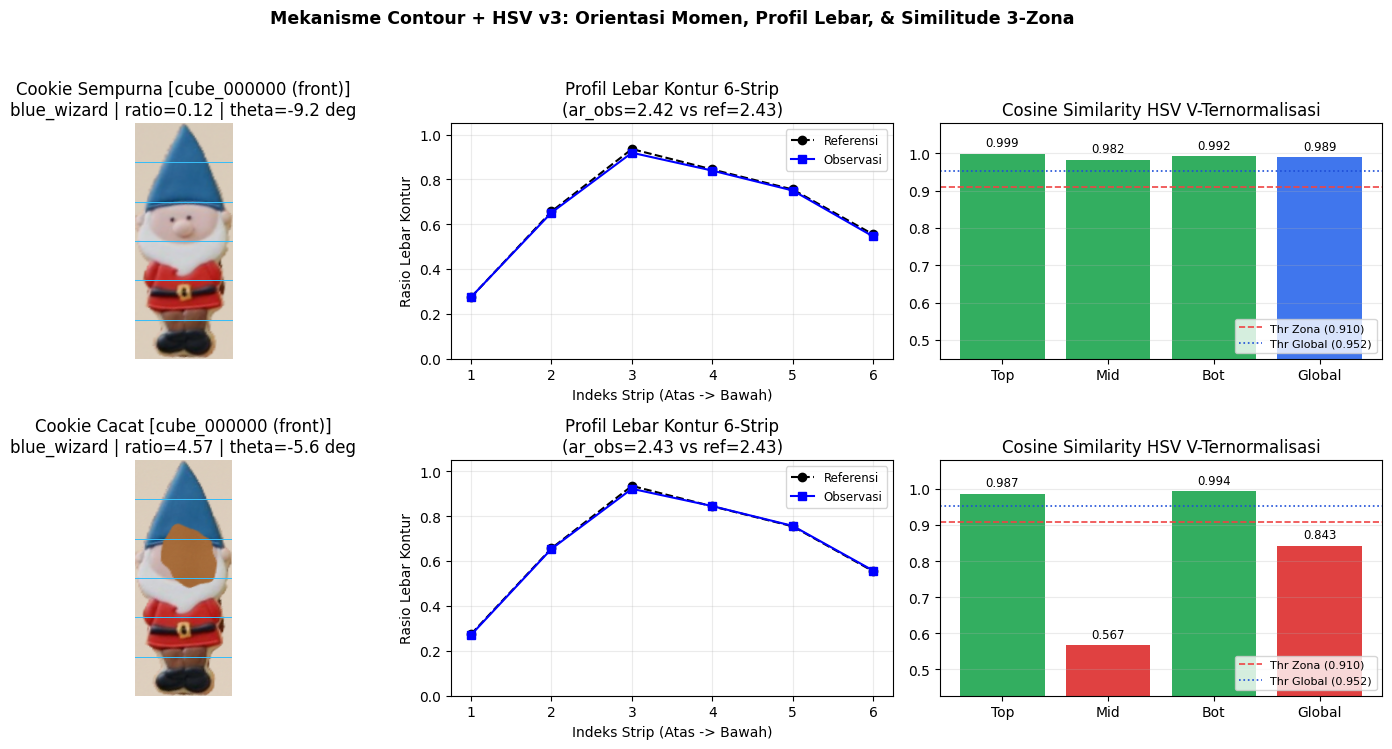

In [10]:
df_chsv_eval = evaluate_and_record_model("contour_hsv", "Contour + HSV", predict_cube_contour_hsv)
display(df_chsv_eval)
df_hidden_chsv = export_hidden_submission("contour_hsv", predict_cube_contour_hsv, "task2_contour")
display(df_hidden_chsv.head(3))

chsv_refs = _prepare_contour_hsv_refs(references)
chsv_pair = {}
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    for ann_v in annotations[:60]:
        with Image.open(io.BytesIO(zf.read(ann_v["image"]))) as im:
            rgb_v = np.asarray(im.convert("RGB"))
        _, dm_v = fit_background_model(rgb_v)
        hx_v, _ = extract_cube_hexagon(rgb_v, dist_map=dm_v)
        vc_v, par_v = compute_vanishing_center(hx_v, rgb=rgb_v)
        fq_v = segment_cube_faces(rgb_v, hx_v, vc_v, parity=par_v)
        for fn_v in FACES:
            wf_v, _ = rectify_face(rgb_v, fq_v[fn_v], CANONICAL_FACE_SIZE)
            cs_v, cm_v = segment_face_cookies(wf_v)
            for c_v in cs_v:
                sc_c = _score_contour_hsv_cookie(wf_v, c_v, chsv_refs, cm_v)
                if not sc_c["is_defective"] and sc_c["defect_ratio"] < 0.70 and "sempurna" not in chsv_pair:
                    chsv_pair["sempurna"] = (wf_v, c_v, cm_v, sc_c, f"{Path(ann_v['image']).stem} ({fn_v})")
                elif sc_c["is_defective"] and "cacat" not in chsv_pair:
                    chsv_pair["cacat"] = (wf_v, c_v, cm_v, sc_c, f"{Path(ann_v['image']).stem} ({fn_v})")
        if len(chsv_pair) == 2:
            break

fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.6))
for row_i, (k_c, label_tag) in enumerate([("sempurna", "Cookie Sempurna"), ("cacat", "Cookie Cacat")]):
    wf_c, c_item, c_med, sc_c, tag_c = chsv_pair[k_c]
    th_c, ar_c = _major_axis_angle_deg(c_item["mask_solid"])
    cand_c = [th_c, th_c + 180.0] + ([0.0, 90.0, 180.0, -90.0] if ar_c < 1.48 else [])
    best_obs_st, best_ref_st, best_rc_c, best_sc_c = None, chsv_refs[sc_c["design_id"]], None, -1e9
    for ang_c in cand_c:
        rc_c = _rotate_crop_patch(wf_c, c_item, ang_c, c_med)
        if rc_c is None:
            continue
        st_o = _extract_contour_zone_stats(rc_c[0], rc_c[1], rc_c[2], n_strips=6)
        s6 = [float(np.dot(a, b)) for a, b in zip(st_o["strips"], best_ref_st["strips"])]
        wp = float(np.mean(np.abs(st_o["widths"] - best_ref_st["widths"])))
        sc_tot = 0.25 * float(np.dot(st_o["g_hist"], best_ref_st["g_hist"])) + 0.75 * (sum(sorted(s6)[1:]) / 5.0 - 0.18 * wp)
        if sc_tot > best_sc_c:
            best_sc_c = sc_tot
            best_obs_st, best_rc_c = st_o, rc_c

    rot_img_c, rot_sol_c, _, _ = best_rc_c
    ys_c, xs_c = np.where(rot_sol_c > 0)
    crop_vis = np.ascontiguousarray(np.clip(rot_img_c[int(ys_c.min()):int(ys_c.max()) + 1, int(xs_c.min()):int(xs_c.max()) + 1], 0, 255), dtype=np.uint8)
    bh_c, bw_c = crop_vis.shape[:2]
    for s_i in range(1, 6):
        y_line = int(round(s_i * bh_c / 6.0))
        cv2.line(crop_vis, (0, y_line), (bw_c - 1, y_line), (56, 189, 248), 1)
    axes[row_i, 0].imshow(crop_vis)
    axes[row_i, 0].set_title(f"{label_tag} [{tag_c}]\n{best_ref_st['name']} | ratio={sc_c['defect_ratio']:.2f} | theta={th_c:.1f} deg")
    axes[row_i, 0].axis("off")

    strips_x = np.arange(1, 7)
    axes[row_i, 1].plot(strips_x, best_ref_st["widths"], "k--o", label="Referensi")
    axes[row_i, 1].plot(strips_x, best_obs_st["widths"], "b-s", label="Observasi")
    axes[row_i, 1].set_xticks(strips_x)
    axes[row_i, 1].set_ylim(0.0, 1.05)
    axes[row_i, 1].set_xlabel("Indeks Strip (Atas -> Bawah)")
    axes[row_i, 1].set_ylabel("Rasio Lebar Kontur")
    axes[row_i, 1].set_title(f"Profil Lebar Kontur 6-Strip\n(ar_obs={best_obs_st['ar']:.2f} vs ref={best_ref_st['ar']:.2f})")
    axes[row_i, 1].legend(fontsize=8.5)
    axes[row_i, 1].grid(alpha=0.25)

    z_labels = ["Top", "Mid", "Bot", "Global"]
    z_vals = [float(np.dot(a, b)) for a, b in zip(best_obs_st["z3"], best_ref_st["z3"])] + [float(np.dot(best_obs_st["g_hist"], best_ref_st["g_hist"]))]
    bar_cols = ["#dc2626" if v < 0.91 else "#16a34a" for v in z_vals[:3]] + ["#dc2626" if z_vals[3] < 0.952 else "#2563eb"]
    axes[row_i, 2].bar(z_labels, z_vals, color=bar_cols, alpha=0.88)
    axes[row_i, 2].axhline(0.910, color="#ef4444", ls="--", lw=1.2, label="Thr Zona (0.910)")
    axes[row_i, 2].axhline(0.952, color="#1d4ed8", ls=":", lw=1.2, label="Thr Global (0.952)")
    axes[row_i, 2].set_ylim(min(0.45, max(0.0, min(z_vals) - 0.14)), 1.08)
    for bi, bv in enumerate(z_vals):
        axes[row_i, 2].text(bi, bv + 0.012, f"{bv:.3f}", ha="center", va="bottom", fontsize=8.5)
    axes[row_i, 2].set_title("Cosine Similarity HSV V-Ternormalisasi")
    axes[row_i, 2].legend(loc="lower right", fontsize=8)
    axes[row_i, 2].grid(axis="y", alpha=0.25)

plt.suptitle("Mekanisme Contour + HSV v3: Orientasi Momen, Profil Lebar, & Similitude 3-Zona", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(FIG_DIR / "task2_non_dl_contour_hsv_v3.png", dpi=150, bbox_inches="tight")
plt.show()

### 11. Progresi Optimasi (`v1 -> v2 -> v3`), Analisis Kegagalan, Perbandingan Lintas Model, & Audit CSV
Kami memvisualisasikan dampak langsung tiap tahap optimasi secara kuantitatif maupun kualitatif (*before vs after* pada *RANSAC vs Umeyama SVD Refit* dan *6-Strip Dual-Anchor* untuk `boundary_cut`), dengan tolok ukur historis `v1` (baseline awal & skor Kaggle publik pertama) dan `v2` (hasil evaluasi 100/200 citra pra-Umeyama Refit dan pra-6-strip: `Exact Match LB = 100%, 95%, 95%, 79%` dan `Hidden Agree = 100%, 91%, 90.5%, 77%`) dibandingkan langsung terhadap eksekusi `v3` aktual. Selanjutnya, kami merangkum seluruh metrik termasuk pemisahan kesalahan per target (`total`, `defective`, `design_count`) serta per kategori cacat (`boundary_cut`, `interior_hole`, `missing_feature`), memeriksa galeri kegagalan nyata, dan mengaudit ke-8 berkas CSV.

> *Catatan Ruang Lingkup (§8)*: Notebook ini khusus membandingkan 4 pendekatan **Non-Deep Learning** Tugas 2. Integrasi komparasi lintas pendekatan dengan **Deep Learning Tugas 2** dilakukan setelah modul `src/task2_dl/` selesai diimplementasikan.

=== Perbandingan Kinerja pada Seluruh 100 Citra Berlabel (split='all') ===


,Model,sec/citra,MAE_total,MAE_defective,MAE_def_on_def_faces,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,Main Multi-Template NCC,2.043,0.0,0.000000,0.000000,0.000000,100.000000,100.0,100.0
1,SIFT + RANSAC,0.633,0.0,0.003333,0.009804,0.003333,99.666667,99.0,98.0
2,ORB + RANSAC,0.579,0.0,0.013333,0.009804,0.003333,99.000000,97.0,96.0
3,Contour + HSV,0.281,0.0,0.036667,0.088235,0.026667,96.333333,89.0,81.0


=== Perbandingan Kinerja pada Split Uji (split='test', n=15) ===


,Model,sec/citra,MAE_total,MAE_defective,MAE_def_on_def_faces,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,Main Multi-Template NCC,2.043,0.0,0.0,0.0,0.000000,100.0,100.0,100.000000
1,SIFT + RANSAC,0.633,0.0,0.0,0.0,0.000000,100.0,100.0,100.000000
2,ORB + RANSAC,0.579,0.0,0.0,0.0,0.022222,100.0,100.0,93.333333
3,Contour + HSV,0.281,0.0,0.0,0.0,0.022222,100.0,100.0,93.333333


=== Rincian MAE per Sisi Kubus untuk Ketiga Target (split='all', n=100) ===


,Model,front_tot,front_def,front_des,right_tot,right_def,right_des,top_tot,top_def,top_des
0,Main Multi-Template NCC,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00,0.00
1,SIFT + RANSAC,0.0,0.01,0.00,0.0,0.00,0.01,0.0,0.00,0.00
2,ORB + RANSAC,0.0,0.01,0.00,0.0,0.03,0.00,0.0,0.00,0.01
3,Contour + HSV,0.0,0.05,0.03,0.0,0.04,0.04,0.0,0.02,0.01


=== Pemisahan Jumlah Kubus Error per Jenis Target (n=100) ===


,Model,Error_total_cubes,Error_defective_cubes,Error_design_cubes
0,Main Multi-Template NCC,0,0,0
1,SIFT + RANSAC,0,1,1
2,ORB + RANSAC,0,3,1
3,Contour + HSV,0,11,8


=== Akurasi Deteksi Jumlah Cacat per Kategori Cacat pada Sisi Terkait ===


,Model,boundary_cut (n=47),interior_hole (n=32),missing_feature (n=31)
0,Main Multi-Template NCC,100.0%,100.0%,100.0%
1,SIFT + RANSAC,97.9%,100.0%,100.0%
2,ORB + RANSAC,97.9%,100.0%,100.0%
3,Contour + HSV,80.9%,96.9%,100.0%


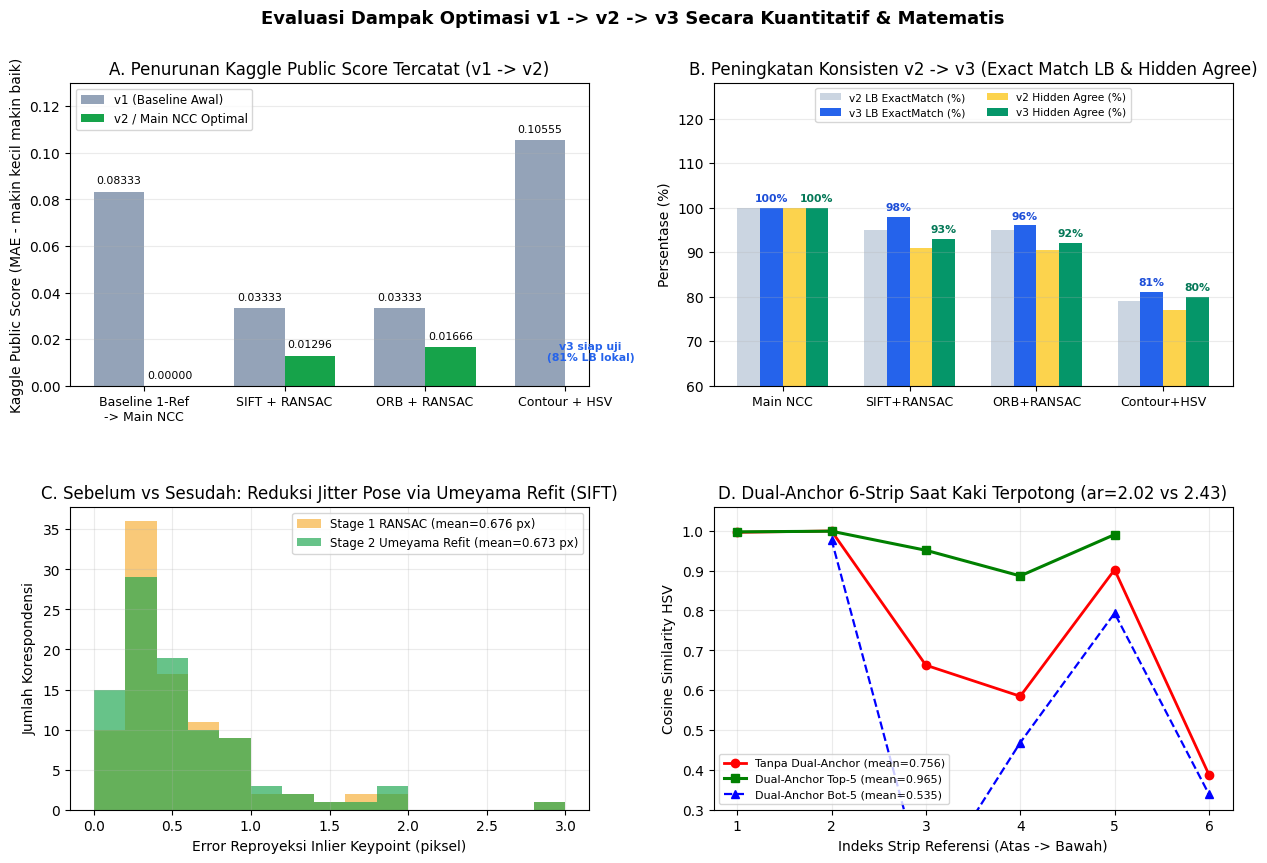

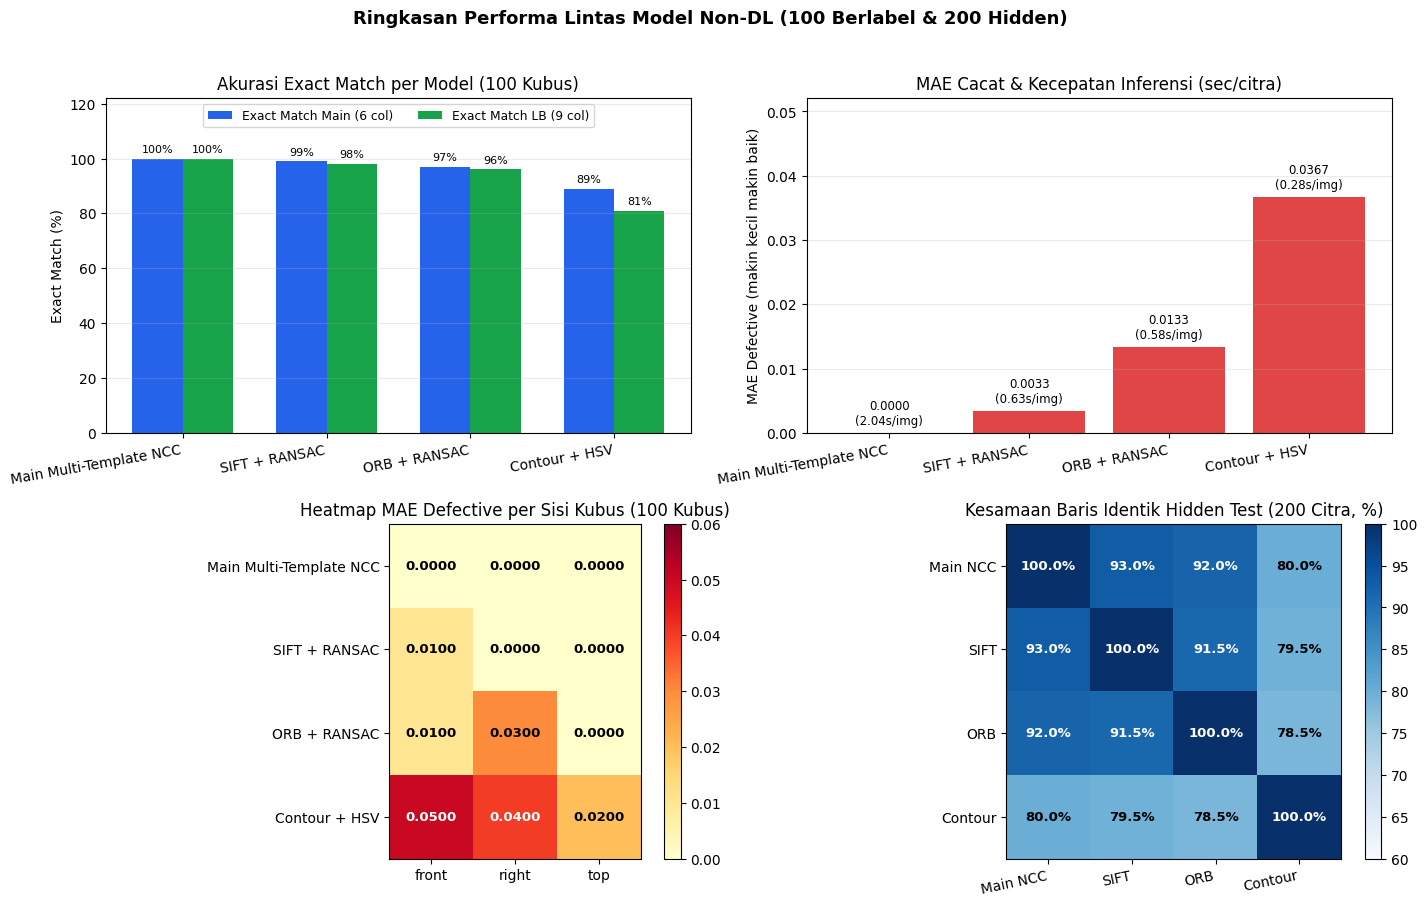

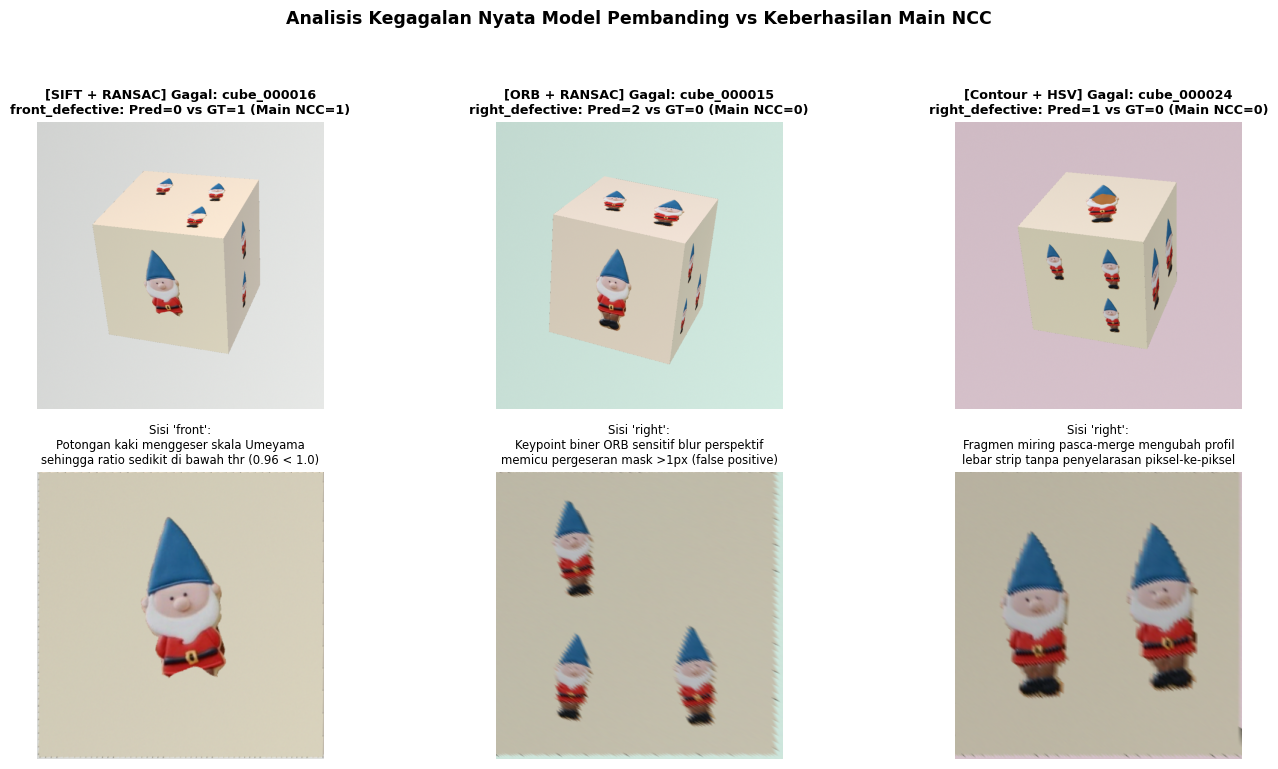


=== Audit Berkas CSV Submisi di submissions/ ===


,model_key,jenis,file,rows,cols,sha256_12,valid
0,main_ncc,leaderboard (10 col),task2_ncc_lb.csv,200,10,a5de17a7ef9a,True
1,main_ncc,main (7 col),task2_ncc_main.csv,200,7,03a4f0239c59,True
2,sift_ransac,leaderboard (10 col),task2_sift_lb.csv,200,10,8fe96d25bb75,True
3,sift_ransac,main (7 col),task2_sift_main.csv,200,7,f9f90c233588,True
4,orb_ransac,leaderboard (10 col),task2_orb_lb.csv,200,10,70f928c5b87e,True
5,orb_ransac,main (7 col),task2_orb_main.csv,200,7,95b6c0fba490,True
6,contour_hsv,leaderboard (10 col),task2_contour_lb.csv,200,10,093b5ec57efa,True
7,contour_hsv,main (7 col),task2_contour_main.csv,200,7,d6d10dd2fd12,True


In [11]:
def build_comparison_table(split_name: str) -> pd.DataFrame:
    comp_rows = []
    for key in ("main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"):
        entry = MODEL_BENCHMARKS[key]
        row_sp = entry["summary_df"].loc[entry["summary_df"]["split"] == split_name].iloc[0].to_dict()
        comp_rows.append(
            {
                "Model": entry["label"],
                "sec/citra": round(entry["sec_per_img"], 3),
                "MAE_total": row_sp["MAE_total"],
                "MAE_defective": row_sp["MAE_defective"],
                "MAE_def_on_def_faces": row_sp["MAE_def_on_def_faces"],
                "MAE_design_count": row_sp["MAE_design_count"],
                "ExactMatch_Face_%": row_sp["ExactMatch_Face_%"],
                "ExactMatch_Main_%": row_sp["ExactMatch_Main_%"],
                "ExactMatch_LB_%": row_sp["ExactMatch_LB_%"],
            }
        )
    return pd.DataFrame(comp_rows)


df_cmp_all = build_comparison_table("all")
df_cmp_test = build_comparison_table("test")
print("=== Perbandingan Kinerja pada Seluruh 100 Citra Berlabel (split='all') ===")
display(df_cmp_all)
print("=== Perbandingan Kinerja pada Split Uji (split='test', n=15) ===")
display(df_cmp_test)

per_face_rows = []
for key in ("main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"):
    pf = MODEL_BENCHMARKS[key]["per_face_all"]
    row_pf = {"Model": MODEL_BENCHMARKS[key]["label"]}
    for fn in FACES:
        row_pf[f"{fn}_tot"] = round(pf[fn]["MAE_total"], 4)
        row_pf[f"{fn}_def"] = round(pf[fn]["MAE_defective"], 4)
        row_pf[f"{fn}_des"] = round(pf[fn]["MAE_design_count"], 4)
    per_face_rows.append(row_pf)
print("=== Rincian MAE per Sisi Kubus untuk Ketiga Target (split='all', n=100) ===")
display(pd.DataFrame(per_face_rows))

# Pemisahan jumlah kubus error menurut jenis target (menghitung objek vs cacat vs desain unik - §8).
err_split_rows = []
yt_idx = df_truth.set_index("image_id")
for key in ("main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"):
    dp_idx = MODEL_BENCHMARKS[key]["pred_train_df"].set_index("image_id").loc[df_truth["image_id"]]
    err_split_rows.append(
        {
            "Model": MODEL_BENCHMARKS[key]["label"],
            "Error_total_cubes": int((dp_idx[[f"{f}_total" for f in FACES]].to_numpy() != yt_idx[[f"{f}_total" for f in FACES]].to_numpy()).any(axis=1).sum()),
            "Error_defective_cubes": int((dp_idx[[f"{f}_defective" for f in FACES]].to_numpy() != yt_idx[[f"{f}_defective" for f in FACES]].to_numpy()).any(axis=1).sum()),
            "Error_design_cubes": int((dp_idx[[f"{f}_design_count" for f in FACES]].to_numpy() != yt_idx[[f"{f}_design_count" for f in FACES]].to_numpy()).any(axis=1).sum()),
        }
    )
print("=== Pemisahan Jumlah Kubus Error per Jenis Target (n=100) ===")
display(pd.DataFrame(err_split_rows))

# Kinerja deteksi cacat per kategori cacat pada tingkat sisi (boundary_cut, interior_hole, missing_feature).
face_defect_cats = []
for ann in annotations:
    img_id = Path(ann["image"]).stem
    by_face = {fn: set() for fn in FACES}
    for inst in ann["instances"]:
        for dt in inst.get("defect_types", []):
            by_face[inst["face"]].add(dt)
    for f in ann["faces"]:
        fn = f["name"]
        if by_face[fn]:
            face_defect_cats.append((img_id, fn, len(f["defective_instance_ids"]), by_face[fn]))

defect_cat_rows = []
for key in ("main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"):
    dp_idx = MODEL_BENCHMARKS[key]["pred_train_df"].set_index("image_id")
    rec_row = {"Model": MODEL_BENCHMARKS[key]["label"]}
    for dcat in ("boundary_cut", "interior_hole", "missing_feature"):
        sub_faces = [(iid, fn, gt_d) for iid, fn, gt_d, dts in face_defect_cats if dcat in dts]
        ok_cnt = sum(1 for iid, fn, gt_d in sub_faces if int(dp_idx.loc[iid, f"{fn}_defective"]) == gt_d)
        rec_row[f"{dcat} (n={len(sub_faces)})"] = f"{100.0 * ok_cnt / max(1, len(sub_faces)):.1f}%"
    defect_cat_rows.append(rec_row)
print("=== Akurasi Deteksi Jumlah Cacat per Kategori Cacat pada Sisi Terkait ===")
display(pd.DataFrame(defect_cat_rows))

lb_keys = ["main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"]
lb_labels = [MODEL_BENCHMARKS[k]["label"] for k in lb_keys]
face_err_mat = np.array([[MODEL_BENCHMARKS[k]["per_face_all"][fn]["MAE_defective"] for fn in FACES] for k in lb_keys], dtype=float)

agree_mat = pd.DataFrame(index=lb_keys, columns=lb_keys, dtype=float)
for k1 in lb_keys:
    for k2 in lb_keys:
        eq_rows = (HIDDEN_LB_DFS[k1].iloc[:, 1:].to_numpy() == HIDDEN_LB_DFS[k2].iloc[:, 1:].to_numpy()).all(axis=1)
        agree_mat.loc[k1, k2] = round(float(eq_rows.mean() * 100.0), 1)

# --- Visual 6: Progresi Optimasi Kuantitatif (Kaggle + v2->v3) & Before-vs-After Matematis ---
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    with Image.open(io.BytesIO(zf.read(annotations[16]["image"]))) as im:
        rgb16 = np.asarray(im.convert("RGB"))
_, dm16 = fit_background_model(rgb16)
hx16, _ = extract_cube_hexagon(rgb16, dist_map=dm16)
vc16, par16 = compute_vanishing_center(hx16, rgb=rgb16)
fq16 = segment_cube_faces(rgb16, hx16, vc16, parity=par16)
wf16_f, _ = rectify_face(rgb16, fq16["front"], CANONICAL_FACE_SIZE)
cs16_f, cm16_f = segment_face_cookies(wf16_f)
comp_bcut = cs16_f[0]

th_bc, _ = _major_axis_angle_deg(comp_bcut["mask_solid"])
rc_bc = _rotate_crop_patch(wf16_f, comp_bcut, th_bc, cm16_f)
st6_bc = _extract_contour_zone_stats(rc_bc[0], rc_bc[1], rc_bc[2], n_strips=6)
ref1_chsv = chsv_refs[1]
s6_full_bc = [float(np.dot(a, b)) for a, b in zip(st6_bc["strips"], ref1_chsv["strips"])]
k_bc = max(3, min(5, int(round(6.0 * st6_bc["ar"] / max(0.5, ref1_chsv["ar"])))))
stk_bc = _extract_contour_zone_stats(rc_bc[0], rc_bc[1], rc_bc[2], n_strips=k_bc)
top_aligned_bc = [float(np.dot(a, b)) for a, b in zip(stk_bc["strips"], ref1_chsv["strips"][:k_bc])]
bot_aligned_bc = [float(np.dot(a, b)) for a, b in zip(stk_bc["strips"], ref1_chsv["strips"][6 - k_bc :])]

re_s, M0_s, Mfin_s, inl_s, tight_s, _, src_s, dst_s, errs0_s, _, _, _, _, _ = vis_by_method["sift"]
errs_fin_s = np.linalg.norm((src_s @ Mfin_s[:, :2].T) + Mfin_s[:, 2] - dst_s, axis=1)

fig_opt = plt.figure(figsize=(15.0, 9.2))
gs = fig_opt.add_gridspec(2, 2, top=0.90, hspace=0.40, wspace=0.24)

ax_a = fig_opt.add_subplot(gs[0, 0])
models_k = ["Baseline 1-Ref\n-> Main NCC", "SIFT + RANSAC", "ORB + RANSAC", "Contour + HSV"]
v1_scores = [0.08333, 0.03333, 0.03333, 0.10555]
v2_scores = [0.00000, 0.01296, 0.01666]
xk = np.arange(len(models_k))
b_v1 = ax_a.bar(xk - 0.18, v1_scores, 0.36, label="v1 (Baseline Awal)", color="#94a3b8")
b_v2 = ax_a.bar(xk[:3] + 0.18, v2_scores, 0.36, label="v2 / Main NCC Optimal", color="#16a34a")
ax_a.set_xticks(xk)
ax_a.set_xticklabels(models_k, fontsize=9)
ax_a.set_ylabel("Kaggle Public Score (MAE - makin kecil makin baik)")
ax_a.set_ylim(0, 0.13)
ax_a.set_title("A. Penurunan Kaggle Public Score Tercatat (v1 -> v2)")
ax_a.legend(loc="upper left", fontsize=8.5)
ax_a.grid(axis="y", alpha=0.25)
for rect in list(b_v1) + list(b_v2):
    hv = rect.get_height()
    ax_a.text(rect.get_x() + rect.get_width() / 2, hv + 0.0025, f"{hv:.5f}", ha="center", va="bottom", fontsize=7.8)
ax_a.text(3 + 0.18, 0.01, "v3 siap uji\n(81% LB lokal)", ha="center", va="bottom", fontsize=7.8, color="#2563eb", fontweight="bold")

ax_b = fig_opt.add_subplot(gs[0, 1])
v2_em_lb = [100.0, 95.0, 95.0, 79.0]
v3_em_lb = list(df_cmp_all["ExactMatch_LB_%"])
v2_hid_ag = [100.0, 91.0, 90.5, 77.0]
v3_hid_ag = [float(agree_mat.loc["main_ncc", k]) for k in lb_keys]
xm = np.arange(4)
ax_b.bar(xm - 0.27, v2_em_lb, 0.18, label="v2 LB ExactMatch (%)", color="#cbd5e1")
ax_b.bar(xm - 0.09, v3_em_lb, 0.18, label="v3 LB ExactMatch (%)", color="#2563eb")
ax_b.bar(xm + 0.09, v2_hid_ag, 0.18, label="v2 Hidden Agree (%)", color="#fcd34d")
ax_b.bar(xm + 0.27, v3_hid_ag, 0.18, label="v3 Hidden Agree (%)", color="#059669")
ax_b.set_xticks(xm)
ax_b.set_xticklabels(["Main NCC", "SIFT+RANSAC", "ORB+RANSAC", "Contour+HSV"], fontsize=9)
ax_b.set_ylim(60, 128)
ax_b.set_ylabel("Persentase (%)")
ax_b.set_title("B. Peningkatan Konsisten v2 -> v3 (Exact Match LB & Hidden Agree)")
ax_b.legend(loc="upper center", ncol=2, fontsize=7.6, frameon=True)
ax_b.grid(axis="y", alpha=0.25)
for xi, (l3, h3) in enumerate(zip(v3_em_lb, v3_hid_ag)):
    ax_b.text(xi - 0.09, l3 + 1.0, f"{l3:.0f}%", ha="center", va="bottom", fontsize=7.8, color="#1d4ed8", fontweight="bold")
    ax_b.text(xi + 0.27, h3 + 1.0, f"{h3:.0f}%", ha="center", va="bottom", fontsize=7.8, color="#047857", fontweight="bold")

ax_c = fig_opt.add_subplot(gs[1, 0])
bins_e = np.linspace(0.0, 3.0, 16)
e0_inl = errs0_s[inl_s]
efin_inl = errs_fin_s[inl_s]
ax_c.hist(e0_inl, bins=bins_e, alpha=0.55, color="#f59e0b", label=f"Stage 1 RANSAC (mean={e0_inl.mean():.3f} px)")
ax_c.hist(efin_inl, bins=bins_e, alpha=0.65, color="#16a34a", label=f"Stage 2 Umeyama Refit (mean={efin_inl.mean():.3f} px)")
ax_c.set_xlabel("Error Reproyeksi Inlier Keypoint (piksel)")
ax_c.set_ylabel("Jumlah Korespondensi")
ax_c.set_title("C. Sebelum vs Sesudah: Reduksi Jitter Pose via Umeyama Refit (SIFT)")
ax_c.legend(fontsize=8.5)
ax_c.grid(alpha=0.25)

ax_d = fig_opt.add_subplot(gs[1, 1])
idx_s = np.arange(1, 7)
ax_d.plot(idx_s, s6_full_bc, "r-o", lw=2, label=f"Tanpa Dual-Anchor (mean={np.mean(s6_full_bc):.3f})")
ax_d.plot(np.arange(1, k_bc + 1), top_aligned_bc, "g-s", lw=2.2, label=f"Dual-Anchor Top-{k_bc} (mean={np.mean(top_aligned_bc):.3f})")
ax_d.plot(np.arange(7 - k_bc, 7), bot_aligned_bc, "b--^", lw=1.6, label=f"Dual-Anchor Bot-{k_bc} (mean={np.mean(bot_aligned_bc):.3f})")
ax_d.set_xticks(idx_s)
ax_d.set_ylim(0.30, 1.06)
ax_d.set_xlabel("Indeks Strip Referensi (Atas -> Bawah)")
ax_d.set_ylabel("Cosine Similarity HSV")
ax_d.set_title(f"D. Dual-Anchor 6-Strip Saat Kaki Terpotong (ar={st6_bc['ar']:.2f} vs {ref1_chsv['ar']:.2f})")
ax_d.legend(loc="lower left", fontsize=8)
ax_d.grid(alpha=0.25)

plt.suptitle("Evaluasi Dampak Optimasi v1 -> v2 -> v3 Secara Kuantitatif & Matematis", fontsize=13, fontweight="bold")
plt.savefig(FIG_DIR / "task2_non_dl_optimization_v1_v2_v3.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Visual 7: Ringkasan Akurasi, MAE+Kecepatan, Heatmap per Sisi, & Kesamaan Hidden ---
fig_cmp, axes_c = plt.subplots(2, 2, figsize=(14.5, 9.2))
x_pos = np.arange(len(df_cmp_all))
w_bar = 0.35
b1 = axes_c[0, 0].bar(x_pos - w_bar / 2, df_cmp_all["ExactMatch_Main_%"], w_bar, label="Exact Match Main (6 col)", color="#2563eb")
b2 = axes_c[0, 0].bar(x_pos + w_bar / 2, df_cmp_all["ExactMatch_LB_%"], w_bar, label="Exact Match LB (9 col)", color="#16a34a")
axes_c[0, 0].set_xticks(x_pos)
axes_c[0, 0].set_xticklabels(df_cmp_all["Model"], rotation=10, ha="right")
axes_c[0, 0].set_ylim(0, 122)
axes_c[0, 0].set_ylabel("Exact Match (%)")
axes_c[0, 0].set_title("Akurasi Exact Match per Model (100 Kubus)")
axes_c[0, 0].legend(loc="upper center", ncol=2, frameon=True, fontsize=8.8)
axes_c[0, 0].grid(axis="y", alpha=0.25)
for rect in list(b1) + list(b2):
    hv = rect.get_height()
    axes_c[0, 0].text(rect.get_x() + rect.get_width() / 2, hv + 1.5, f"{hv:.0f}%", ha="center", va="bottom", fontsize=8)

axes_c[0, 1].bar(x_pos, df_cmp_all["MAE_defective"], color="#dc2626", alpha=0.85)
axes_c[0, 1].set_xticks(x_pos)
axes_c[0, 1].set_xticklabels(df_cmp_all["Model"], rotation=10, ha="right")
axes_c[0, 1].set_ylabel("MAE Defective (makin kecil makin baik)")
axes_c[0, 1].set_title("MAE Cacat & Kecepatan Inferensi (sec/citra)")
axes_c[0, 1].grid(axis="y", alpha=0.25)
max_mae_def = max(0.01, float(df_cmp_all["MAE_defective"].max()))
for xi, (mae_v, spd_v) in enumerate(zip(df_cmp_all["MAE_defective"], df_cmp_all["sec/citra"])):
    axes_c[0, 1].text(xi, mae_v + 0.025 * max_mae_def, f"{mae_v:.4f}\n({spd_v:.2f}s/img)", ha="center", va="bottom", fontsize=8.5)
axes_c[0, 1].set_ylim(0, max_mae_def * 1.42)

im0 = axes_c[1, 0].imshow(face_err_mat, cmap="YlOrRd", vmin=0.0, vmax=max(0.06, float(face_err_mat.max())))
axes_c[1, 0].set_xticks(range(len(FACES)))
axes_c[1, 0].set_xticklabels(FACES)
axes_c[1, 0].set_yticks(range(len(lb_labels)))
axes_c[1, 0].set_yticklabels(lb_labels)
axes_c[1, 0].set_title("Heatmap MAE Defective per Sisi Kubus (100 Kubus)")
for ri in range(face_err_mat.shape[0]):
    for ci in range(face_err_mat.shape[1]):
        val = face_err_mat[ri, ci]
        axes_c[1, 0].text(ci, ri, f"{val:.4f}", ha="center", va="center", color="white" if val > 0.03 else "black", fontsize=9.5, fontweight="bold")
plt.colorbar(im0, ax=axes_c[1, 0], fraction=0.046, pad=0.04)

ag_arr = agree_mat.to_numpy(dtype=float)
im1 = axes_c[1, 1].imshow(ag_arr, cmap="Blues", vmin=60.0, vmax=100.0)
axes_c[1, 1].set_xticks(range(len(lb_keys)))
axes_c[1, 1].set_xticklabels(["Main NCC", "SIFT", "ORB", "Contour"], rotation=12, ha="right")
axes_c[1, 1].set_yticks(range(len(lb_keys)))
axes_c[1, 1].set_yticklabels(["Main NCC", "SIFT", "ORB", "Contour"])
axes_c[1, 1].set_title("Kesamaan Baris Identik Hidden Test (200 Citra, %)")
for ri in range(ag_arr.shape[0]):
    for ci in range(ag_arr.shape[1]):
        val = ag_arr[ri, ci]
        axes_c[1, 1].text(ci, ri, f"{val:.1f}%", ha="center", va="center", color="white" if val > 85.0 else "black", fontsize=9.5, fontweight="bold")
plt.colorbar(im1, ax=axes_c[1, 1], fraction=0.046, pad=0.04)

plt.suptitle("Ringkasan Performa Lintas Model Non-DL (100 Berlabel & 200 Hidden)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIG_DIR / "task2_non_dl_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Visual 8: Galeri Kasus Kegagalan Nyata (Failure Analysis - Section 8 PROJECT_SPEC) ---
def _diagnose_failure(m_key: str, t_col: str, p_v: int, g_v: int) -> str:
    if t_col.endswith("_defective"):
        if m_key == "sift_ransac" and p_v < g_v:
            return "Potongan kaki menggeser skala Umeyama\nsehingga ratio sedikit di bawah thr (0.96 < 1.0)"
        if m_key == "orb_ransac" and p_v > g_v:
            return "Keypoint biner ORB sensitif blur perspektif\nmemicu pergeseran mask >1px (false positive)"
        if m_key == "contour_hsv" and p_v > g_v:
            return "Fragmen miring pasca-merge mengubah profil\nlebar strip tanpa penyelarasan piksel-ke-piksel"
        return "Kesalahan klasifikasi ambang cacat sisi terkait"
    return "Keypoint/strip terbatas di sudut miring memicu\ndeteksi palsu desain tambahan (>1 unik)"


fail_specs = []
cols_lb_no_id = cube_columns(True)[1:]
for m_key in ("sift_ransac", "orb_ransac", "contour_hsv"):
    df_p_m = MODEL_BENCHMARKS[m_key]["pred_train_df"]
    chosen = None
    # Prioritaskan contoh error defective pada split train/val agar diagnosis akurat & mudah diinspeksi.
    for prefer_def in (True, False):
        for idx_r in range(len(df_truth)):
            gt_r = df_truth.iloc[idx_r]
            pr_r = df_p_m.iloc[idx_r]
            diffs = [(c, int(pr_r[c]), int(gt_r[c])) for c in cols_lb_no_id if int(pr_r[c]) != int(gt_r[c])]
            if not diffs:
                continue
            hit_d = [d for d in diffs if (d[0].endswith("_defective") if prefer_def else True)]
            if hit_d:
                t_col, p_v, g_v = hit_d[0]
                t_face = t_col.split("_")[0]
                chosen = (MODEL_BENCHMARKS[m_key]["label"], idx_r, gt_r["image_id"], t_face, t_col, p_v, g_v, _diagnose_failure(m_key, t_col, p_v, g_v))
                break
        if chosen is not None:
            break
    if chosen is not None:
        fail_specs.append(chosen)

fig_f, axes_f = plt.subplots(2, len(fail_specs), figsize=(14.5, 7.8))
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    for ci, (mlbl, idx_r, img_id, t_face, t_col, p_v, g_v, diag_txt) in enumerate(fail_specs):
        with Image.open(io.BytesIO(zf.read(annotations[idx_r]["image"]))) as im:
            rgb_f = np.asarray(im.convert("RGB"))
        _, dm_f = fit_background_model(rgb_f)
        hx_f, _ = extract_cube_hexagon(rgb_f, dist_map=dm_f)
        vc_f, par_f = compute_vanishing_center(hx_f, rgb=rgb_f)
        fq_f = segment_cube_faces(rgb_f, hx_f, vc_f, parity=par_f)
        wf_f, _ = rectify_face(rgb_f, fq_f[t_face], CANONICAL_FACE_SIZE)
        axes_f[0, ci].imshow(rgb_f)
        axes_f[0, ci].set_title(f"[{mlbl}] Gagal: {img_id}\n{t_col}: Pred={p_v} vs GT={g_v} (Main NCC={g_v})", fontsize=9.2, fontweight="bold")
        axes_f[1, ci].imshow(wf_f)
        axes_f[1, ci].set_title(f"Sisi '{t_face}':\n{diag_txt}", fontsize=8.4)
        axes_f[0, ci].axis("off")
        axes_f[1, ci].axis("off")

plt.suptitle("Analisis Kegagalan Nyata Model Pembanding vs Keberhasilan Main NCC", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(FIG_DIR / "task2_non_dl_failure_cases.png", dpi=150, bbox_inches="tight")
plt.show()

submission_specs = [
    ("main_ncc", "task2_ncc_lb.csv", True),
    ("main_ncc", "task2_ncc_main.csv", False),
    ("sift_ransac", "task2_sift_lb.csv", True),
    ("sift_ransac", "task2_sift_main.csv", False),
    ("orb_ransac", "task2_orb_lb.csv", True),
    ("orb_ransac", "task2_orb_main.csv", False),
    ("contour_hsv", "task2_contour_lb.csv", True),
    ("contour_hsv", "task2_contour_main.csv", False),
]

audit_rows = []
for m_key, fname, is_lb in submission_specs:
    fpath = ROOT / "submissions" / fname
    df_chk = pd.read_csv(fpath, dtype={"image_id": str})
    validate_cube_predictions(df_chk, sample_ids, len(references), leaderboard=is_lb)
    audit_rows.append(
        {
            "model_key": m_key,
            "jenis": "leaderboard (10 col)" if is_lb else "main (7 col)",
            "file": fname,
            "rows": len(df_chk),
            "cols": df_chk.shape[1],
            "sha256_12": hashlib.sha256(fpath.read_bytes()).hexdigest()[:12],
            "valid": True,
        }
    )

print("\n=== Audit Berkas CSV Submisi di submissions/ ===")
display(pd.DataFrame(audit_rows))

### 12. Daftar Referensi

Bradski, G. (2000). The OpenCV library. *Dr. Dobb's Journal*, *25*(11), 120–125.

Fischler, M. A., & Bolles, R. C. (1981). Random sample consensus: A paradigm for model fitting with applications to image analysis and automated cartography. *Communications of the ACM*, *24*(6), 381–395. https://doi.org/10.1145/358669.358692

Gonzalez, R. C., & Woods, R. E. (2018). *Digital image processing* (4th ed.). Pearson.

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hartley, R., & Zisserman, A. (2004). *Multiple view geometry in computer vision* (2nd ed.). Cambridge University Press.

Hu, M.-K. (1962). Visual pattern recognition by moment invariants. *IRE Transactions on Information Theory*, *8*(2), 179–187. https://doi.org/10.1109/TIT.1962.1057692

Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics*, *35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732

Lewis, J. P. (1995). Fast template matching. In *Proceedings of Vision Interface '95* (pp. 120–123). Canadian Image Processing and Pattern Recognition Society.

Lowe, D. G. (2004). Distinctive image features from scale-invariant keypoints. *International Journal of Computer Vision*, *60*(2), 91–110. https://doi.org/10.1023/B:VISI.0000029664.99615.94

OpenCV Team. (2026). *OpenCV 4.x documentation: Camera calibration and 3D reconstruction (`calib3d`), 2D features framework (`features2d`), and image processing (`imgproc`)*. https://docs.opencv.org/4.x/

Rahadianti, L., & Rachmadi, M. F. (2026). *Basic image processing 1 – Spatial domain* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Basic image processing 2 – Frequency domain* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Feature matching, recognition (object detection) and registration* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Image features and recognition (classification)* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Image segmentation and morphology* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rublee, E., Rabaud, V., Konolige, K., & Bradski, G. (2011). ORB: An efficient alternative to SIFT or SURF. In *2011 International Conference on Computer Vision (ICCV)* (pp. 2564–2571). IEEE. https://doi.org/10.1109/ICCV.2011.6126544

Szeliski, R. (2022). *Computer vision: Algorithms and applications* (2nd ed.). Springer. https://doi.org/10.1007/978-3-030-34372-9

Umeyama, S. (1991). Least-squares estimation of transformation parameters between two point patterns. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, *13*(4), 376–380. https://doi.org/10.1109/34.88573